<a href="https://colab.research.google.com/github/Racsok/mineria/blob/desarrollo/analisis_dataset_FIFA_modelos_numericos.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Análisis de dataset FIFA — Regularización con Ridge y Lasso
- Juan Pablo Mosquera
- David Zahid Riveros
- Oscar Manuel Contreras Gacha
- Anderson David Arenas Gutierrez

In [1]:
#%pip uninstall pandas-profiling
#%pip install --upgrade ydata-profiling setuptools

In [2]:
import math
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Scikit-Learn preprocessing & imputation
from sklearn.preprocessing import (
    MinMaxScaler, StandardScaler, RobustScaler,
    OneHotEncoder, MaxAbsScaler
)
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.svm import LinearSVC
from sklearn.model_selection import StratifiedKFold, cross_validate

# Models & validation
from sklearn.model_selection import train_test_split
from sklearn.base import clone
from sklearn.neighbors import KNeighborsRegressor, KNeighborsClassifier
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier, plot_tree, export_text
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.naive_bayes import GaussianNB, MultinomialNB
from sklearn.svm import SVC

# Metrics
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, f1_score,
    precision_score, recall_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay, mean_absolute_error, r2_score
)

# Pandas config & RNG
pd.set_option("display.width", 110)
rng = np.random.default_rng(2026)
print("pandas", pd.__version__)

pandas 2.2.3


In [3]:
URL_DATASET = "https://raw.githubusercontent.com/Racsok/mineria/desarrollo/datasets/fifa_eda_stats.csv"

df = pd.read_csv(
    URL_DATASET,
    encoding="utf-8-sig",
    low_memory=False
)

print(f"Filas: {df.shape[0]}")
print(f"Columnas: {df.shape[1]}")

df.head()

Filas: 18207
Columnas: 57


,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,...,Composure,Marking,StandingTackle,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause
0,158023,L. Messi,31,Argentina,94,94,FC Barcelona,€110.5M,€565K,Left,...,96.0,33.0,28.0,26.0,6.0,11.0,15.0,14.0,8.0,€226.5M
1,20801,Cristiano Ronaldo,33,Portugal,94,94,Juventus,€77M,€405K,Right,...,95.0,28.0,31.0,23.0,7.0,11.0,15.0,14.0,11.0,€127.1M
2,190871,Neymar Jr,26,Brazil,92,93,Paris Saint-Germain,€118.5M,€290K,Right,...,94.0,27.0,24.0,33.0,9.0,9.0,15.0,15.0,11.0,€228.1M
3,193080,De Gea,27,Spain,91,93,Manchester United,€72M,€260K,Right,...,68.0,15.0,21.0,13.0,90.0,85.0,87.0,88.0,94.0,€138.6M
4,192985,K. De Bruyne,27,Belgium,91,92,Manchester City,€102M,€355K,Right,...,88.0,68.0,58.0,51.0,15.0,13.0,5.0,10.0,13.0,€196.4M


## Dataset
El dataset trabaja sobre estadisticas numericas del rendimiento de jugadores de futbol dentro del FIFA, cuenta con 57 columnas y la columna objetivo sobre la cual se analizan los datos es el valor monetario de un jugador en el mercado.

link dataset: https://github.com/Racsok/mineria/blob/desarrollo/datasets/fifa_eda_stats.csv
            https://www.kaggle.com/datasets/mukeshmanral/fifa-data-for-eda-and-stats

# Perfilado y limpieza

Las columnas Value, Wage y Release Clause vienen como strings con formato tipo "€110.5M", "€565K" o "€0". Esto impide cualquier operación estadística (correlación, media, escalado) porque pandas las trata como texto. La función convert_value_to_numeric:
Devuelve None si el valor es nulo o no es string (control defensivo).

* Elimina el símbolo € y espacios.
* Si contiene 'M', multiplica el número por 1 000 000 (millones).
* Si contiene 'K', multiplica por 1 000 (miles).
* Si es exactamente "0", devuelve 0.0.
* En cualquier otro caso intenta convertirlo a float; si falla, devuelve None.

In [4]:
"""Limpieza de valores de dinero"""
def convert_value_to_numeric(value_str):
    if pd.isna(value_str) or not isinstance(value_str, str):
        return None
    value_str = value_str.replace('€', '').strip()
    if 'M' in value_str:
        return float(value_str.replace('M', '')) * 1_000_000
    elif 'K' in value_str:
        return float(value_str.replace('K', '')) * 1_000
    elif value_str == '0':
        return 0.0
    else:
        try:
            return float(value_str)
        except ValueError:
            return None
df['Value'] = df['Value'].apply(convert_value_to_numeric)
df['Wage'] = df['Wage'].apply(convert_value_to_numeric)
df['Release Clause'] = df['Release Clause'].apply(convert_value_to_numeric)

In [5]:
print(df["Value"].value_counts(normalize=True).round(3))

Value
1100000.0     0.024
375000.0      0.020
425000.0      0.019
325000.0      0.019
450000.0      0.019
              ...  
63000000.0    0.000
51500000.0    0.000
53500000.0    0.000
58000000.0    0.000
81000000.0    0.000
Name: proportion, Length: 217, dtype: float64


## Perfilado

Se Ejecuta la función de perfilado que recorre todas las columnas del DataFrame y devuelve una tabla resumen con:

* tipo: el dtype de la columna (útil para detectar numéricas disfrazadas de texto).
* distintos: número de valores únicos (nunique), para medir cardinalidad.
* faltan_%: porcentaje de nulos (isna().mean() * 100), redondeado a 1 decimal.
* moda: el valor más frecuente (s.mode().iloc[0]), con control por si la columna está vacía.
* Para columnas numéricas, además: min, mediana, media y max.

Finalmente se hace set_index("columna") para que cada fila quede identificada por el nombre de la variable. Este perfil es clave porque expone de un vistazo tres problemas: la columna Loaned From con 93.1 % de nulos, Height y Weight guardadas como strings, y Release Clause con 8.6 % de faltantes.

In [6]:
def perfilar(df):
    filas = []
    for col in df.columns:
        s = df[col]
        fila = {
            "columna":   col,
            "tipo":      str(s.dtype),
            "distintos": s.nunique(),
            "faltan_%":  round(s.isna().mean() * 100, 1),
            "moda":      s.mode().iloc[0] if not s.mode().empty else None,
        }
        if pd.api.types.is_numeric_dtype(s):
            fila["min"]     = round(s.min(), 2)
            fila["mediana"] = round(s.median(), 2)
            fila["media"]   = round(s.mean(), 2)
            fila["max"]     = round(s.max(), 2)
        filas.append(fila)
    return pd.DataFrame(filas).set_index("columna")

perfilar(df)


,tipo,distintos,faltan_%,moda,min,mediana,media,max
columna,,,,,,,,
ID,int64,18207,0.0,16,16.0,221759.0,214298.34,246620.0
Name,object,17194,0.0,J. Rodríguez,NaN,NaN,NaN,NaN
Age,int64,29,0.0,21,16.0,25.0,25.12,45.0
Nationality,object,164,0.0,England,NaN,NaN,NaN,NaN
Overall,int64,48,0.0,66,46.0,66.0,66.24,94.0
Potential,int64,47,0.0,70,48.0,71.0,71.31,95.0
Club,object,651,1.3,AS Monaco,NaN,NaN,NaN,NaN
Value,float64,217,0.0,1100000.0,0.0,675000.0,2410695.89,118500000.0
Wage,float64,144,0.0,1000.0,0.0,3000.0,9731.31,565000.0


## Tres problemas encontrados y su solución

* **`Loaned From` con 93.1% de datos nulos:**  
  La gran mayoría de jugadores no están cedidos a préstamo, lo que genera una columna desierta de casi solo faltantes.  
  * **Solución:** Eliminar la columna por falta de varianza o convertirla en una bandera binaria `is_loaned` (1 si tiene club de origen, 0 si es `NaN`).

* **Valores numéricos guardados como texto (`Height` y `Weight`):**  
  Tienen formato de cadena tipo `6'0` y `165lbs`, lo que impide su análisis estadístico y cálculo de correlación directa.  
  * **Solución:** Aplicar una función de transformación en Pandas para convertir `Height` a centímetros y `Weight` a kilogramos (o libras numéricas) y castearlas a tipo `float64`.

* **Nulos masivos en cláusula de rescisión (`Release Clause` con 8.6% de faltantes):**  
  Existen 1,564 jugadores sin cláusula asignada en la base de datos.  
  * **Solución:** Imputar los faltantes calculando una estimación basada en la relación proporcional entre `Value` y `Overall`, o asignar 0 si el contrato no contempla dicha cláusula.

---

## Columnas objetivo y su reparto

###Numerica Value
Al ser **`Value`** una variable continua económica (target de regresión), el método `value_counts(normalize=True)` se utiliza para observar la concentración del mercado o agrupar por rangos. Su reparto estadístico directo muestra:

* **Mínimo:** €0.0
* **Mediana:** €675,000.0
* **Media:** €2,410,695.89
* **Máximo:** €118,500,000.0

*(El reparto de `Value` presenta un marcado sesgo positivo a la derecha [right-skewed], donde más del 50% de los jugadores tiene un valor de mercado inferior a €675,000, mientras que una élite de superestrellas eleva la media a €2.4M y alcanza un pico de €118.5M).*

### Categorica position
Usaremos las variables carateristicas del jufador para oredecir que posicion e jugara



## Limpieza y arreglos

### Solución al Problema 1: Columna `Loaned From` con valores nulos

Se crea una nueva columna `is_loaned` que indica si el jugador está cedido (1) o no (0). Posteriormente, se elimina la columna original `Loaned From`.

In [7]:
# Crear la columna binaria 'is_loaned': 1 si el jugador está cedido (no es NaN en 'Loaned From'), 0 en caso contrario.
df['is_loaned'] = df['Loaned From'].notna().astype(int)

# Eliminar la columna original 'Loaned From' ya que la nueva columna captura la información relevante.
df = df.drop(columns=['Loaned From'])

# Mostrar las primeras filas del DataFrame con la nueva columna y la columna eliminada
display(df[['Name', 'Club', 'is_loaned']].head())

# Verificar el tipo de datos y la ausencia de la columna original
print(df[['is_loaned']].info())

,Name,Club,is_loaned
0,L. Messi,FC Barcelona,0
1,Cristiano Ronaldo,Juventus,0
2,Neymar Jr,Paris Saint-Germain,0
3,De Gea,Manchester United,0
4,K. De Bruyne,Manchester City,0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 1 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   is_loaned  18207 non-null  int64
dtypes: int64(1)
memory usage: 142.4 KB
None


### Solución al Problema 2: Valores numéricos guardados como texto (`Height` y `Weight`)

Se convierten las columnas `Height` y `Weight` de formato texto a numérico. Para `Height`, se convierte de pies y pulgadas a centímetros. Para `Weight`, se elimina la unidad 'lbs' y se convierte a float.

In [8]:
# Función para convertir altura de pies'pulgadas a centímetros
def convert_height_to_cm(height_str):
    if pd.isna(height_str) or not isinstance(height_str, str):
        return None
    try:
        feet, inches = map(int, height_str.replace('"', '').split("'"))
        return (feet * 30.48) + (inches * 2.54)
    except ValueError:
        return None

# Función para convertir peso de 'Xlbs' a un valor numérico en libras
def convert_weight_to_lbs(weight_str):
    if pd.isna(weight_str) or not isinstance(weight_str, str):
        return None
    try:
        return float(weight_str.replace('lbs', ''))
    except ValueError:
        return None

# Aplicar las funciones de conversión a las columnas 'Height' y 'Weight'
df['Height_cm'] = df['Height'].apply(convert_height_to_cm)
df['Weight_lbs'] = df['Weight'].apply(convert_weight_to_lbs)

# Eliminar las columnas originales 'Height' y 'Weight' si ya no son necesarias
df = df.drop(columns=['Height', 'Weight'])

# Mostrar las primeras filas del DataFrame con las nuevas columnas y las columnas eliminadas
display(df[['Name', 'Height_cm', 'Weight_lbs']].head())

# Verificar el tipo de datos de las nuevas columnas
print(df[['Height_cm', 'Weight_lbs']].info())

,Name,Height_cm,Weight_lbs
0,L. Messi,170.18,159.0
1,Cristiano Ronaldo,187.96,183.0
2,Neymar Jr,175.26,150.0
3,De Gea,193.04,168.0
4,K. De Bruyne,180.34,154.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 2 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Height_cm   18159 non-null  float64
 1   Weight_lbs  18159 non-null  float64
dtypes: float64(2)
memory usage: 284.6 KB
None


### Solución al Problema 3: Nulos en la columna `Release Clause`

Release Clause tenía 1 564 valores nulos (8.6 %). La decisión de negocio adoptada es que un nulo significa que el jugador no tiene cláusula de rescisión, lo cual es perfectamente válido en el mundo real. Por eso se imputa con 0 en lugar de con media o mediana: imputar con la media inventaría un contrato que no existe y distorsionaría la distribución; imputar con 0 preserva el significado real ("sin cláusula"). Se verifica con isnull().sum() que ya no queden nulos y con df.info() que el tipo siga siendo float64.

In [9]:
# Imputar los valores nulos en 'Release Clause' con 0
df['Release Clause'] = df['Release Clause'].fillna(0)

# Verificar el número de valores nulos después de la imputación
print(f"Valores nulos en 'Release Clause' después de la imputación: {df['Release Clause'].isnull().sum()}")

# Mostrar una descripción estadística de la columna 'Release Clause' para verificar los cambios
display(df[['Name', 'Club', 'Value', 'Release Clause']].head())

# Verificar el tipo de datos de la columna 'Release Clause'
print(df[['Release Clause']].info())

Valores nulos en 'Release Clause' después de la imputación: 0


,Name,Club,Value,Release Clause
0,L. Messi,FC Barcelona,110500000.0,226500000.0
1,Cristiano Ronaldo,Juventus,77000000.0,127100000.0
2,Neymar Jr,Paris Saint-Germain,118500000.0,228100000.0
3,De Gea,Manchester United,72000000.0,138600000.0
4,K. De Bruyne,Manchester City,102000000.0,196400000.0


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 18207 entries, 0 to 18206
Data columns (total 1 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   Release Clause  18207 non-null  float64
dtypes: float64(1)
memory usage: 142.4 KB
None


## Descripcion

In [10]:
df.describe()

,ID,Age,Overall,Potential,Value,Wage,International Reputation,Weak Foot,Skill Moves,Jersey Number,...,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause,is_loaned,Height_cm,Weight_lbs
count,18207.000000,18207.000000,18207.000000,18207.000000,1.820700e+04,18207.000000,18159.000000,18159.000000,18159.000000,18147.000000,...,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,18159.000000,1.820700e+04,18207.000000,18159.000000,18159.000000
mean,214298.338606,25.122206,66.238699,71.307299,2.410696e+06,9731.312133,1.113222,2.947299,2.361308,19.546096,...,45.661435,16.616223,16.391596,16.232061,16.388898,16.710887,4.191200e+06,0.069424,181.257584,165.979129
std,29965.244204,4.669943,6.908930,6.136496,5.594933e+06,21999.290406,0.394031,0.660456,0.756164,15.947765,...,21.289135,17.695349,16.906900,16.502864,17.034669,17.955119,1.070778e+07,0.254180,6.730145,15.593344
min,16.000000,16.000000,46.000000,48.000000,0.000000e+00,0.000000,1.000000,1.000000,1.000000,1.000000,...,3.000000,1.000000,1.000000,1.000000,1.000000,1.000000,0.000000e+00,0.000000,154.940000,110.000000
25%,200315.500000,21.000000,62.000000,67.000000,3.000000e+05,1000.000000,1.000000,3.000000,2.000000,8.000000,...,24.000000,8.000000,8.000000,8.000000,8.000000,8.000000,3.920000e+05,0.000000,175.260000,154.000000
50%,221759.000000,25.000000,66.000000,71.000000,6.750000e+05,3000.000000,1.000000,3.000000,2.000000,17.000000,...,52.000000,11.000000,11.000000,11.000000,11.000000,11.000000,1.000000e+06,0.000000,180.340000,165.000000
75%,236529.500000,28.000000,71.000000,75.000000,2.000000e+06,9000.000000,1.000000,3.000000,3.000000,26.000000,...,64.000000,14.000000,14.000000,14.000000,14.000000,14.000000,3.000000e+06,0.000000,185.420000,176.000000
max,246620.000000,45.000000,94.000000,95.000000,1.185000e+08,565000.000000,5.000000,5.000000,5.000000,99.000000,...,91.000000,90.000000,92.000000,91.000000,90.000000,94.000000,2.281000e+08,1.000000,205.740000,243.000000


## Imputación de los datos
Muchas columnas presentan exactamente la misma cantidad de nulos, por lo que se procede a mirar la cantidad de jugadores con nulos en todas estas variables, y borrarlos ya que no aportan ningun valor.

Los Nulos en variables como club, joined, y contract valid until, tienen sentido en el negocio ya que un jugador sin club no tiene contrato, y es valido, se reemplazan los nulos por sin club y no disponible, para los jugadores sin jersey se deja un -1

### "Height_cm", "Weight_lbs", "Crossing"


In [11]:
columnas_principales = [
    "Height_cm", "Weight_lbs", "Crossing"
]

columnas_disponibles = [
    columna for columna in columnas_principales
    if columna in df.columns
]

filas_vacias_principales = df[columnas_disponibles].isna().all(axis=1)
display(df.loc[filas_vacias_principales].head(10))

,ID,Name,Age,Nationality,Overall,Potential,Club,Value,Wage,Preferred Foot,...,SlidingTackle,GKDiving,GKHandling,GKKicking,GKPositioning,GKReflexes,Release Clause,is_loaned,Height_cm,Weight_lbs
13236,177971,J. McNulty,33,Scotland,62,62,Rochdale,120000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13237,195380,J. Barrera,29,Nicaragua,62,62,Boyacá Chicó FC,300000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13238,139317,J. Stead,35,England,62,62,Notts County,140000.0,3000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13239,240437,A. Semprini,20,Italy,62,72,Brescia,425000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13240,209462,R. Bingham,24,England,62,66,Hamilton Academical FC,400000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13241,219702,K. Dankowski,21,Poland,62,72,Śląsk Wrocław,425000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13242,225590,I. Colman,23,Argentina,62,70,Club Atlético Aldosivi,450000.0,2000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13243,233782,M. Feeney,19,England,62,78,Everton,600000.0,5000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13244,239158,R. Minor,30,Denmark,62,62,Hobro IK,230000.0,2000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN
13245,242998,Klauss,21,Brazil,62,69,HJK Helsinki,425000.0,1000.0,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,0.0,0,NaN,NaN


Se cuenta cuántas filas cumplen la condición anterior y se eliminan Después se resetea el índice para que no queden huecos en la numeración. Se imprimen el número de filas eliminadas (48) y el nuevo tamaño del DataFrame (18159 × 57) para dejar constancia de la pérdida de datos.

In [12]:
filas_eliminadas = filas_vacias_principales.sum()

df = df.loc[~filas_vacias_principales].copy()
df.reset_index(drop=True, inplace=True)

print("Jugadores eliminados:", filas_eliminadas)
print("Nuevo tamaño del DataFrame:", df.shape)

Jugadores eliminados: 48
Nuevo tamaño del DataFrame: (18159, 57)


### "Club", "Joined" y "Contract"

Ahora se imputan los nulos que sí tienen sentido de negocio:

* Club → "Sin club": un jugador sin equipo no tiene club asignado, y eso es un estado real (agentes libres).
* Jersey Number → -1: se usa un valor centinela negativo para distinguir "sin dorsal asignado" de un dorsal real (que siempre es positivo).
* Joined → "Fecha no disponible": los jugadores sin club tampoco tienen fecha de incorporación.
* Contract Valid Until → "No disponible": mismo razonamiento, no hay contrato si no hay club.

Se verifica imprimiendo el conteo de nulos en Club (debe ser 0) y value_counts() para ver la distribución del club más común.

In [13]:
df["Club"] = df["Club"].fillna("Sin club")
df["Jersey Number"] = df["Jersey Number"].fillna(-1)
df["Joined"] = df["Joined"].fillna("Fecha no disponible")
df["Contract Valid Until"] = df["Contract Valid Until"].fillna("No disponible")

print("Nulos en Club:", df["Club"].isna().sum())
print(df["Club"].value_counts().head())

Nulos en Club: 0
Club
Sin club             241
RC Celta              33
Borussia Dortmund     33
Valencia CF           33
AS Monaco             33
Name: count, dtype: int64


Filtramos el DataFrame para quedarse solo con los jugadores marcados como "Sin club" y muestra las columnas Name, Jersey Number, Joined y Contract Valid Until con display. El objetivo es verificar la coherencia de la imputación anterior: si un jugador no tiene club, esperamos que también tenga Jersey Number = -1, Joined = "Fecha no disponible" y Contract Valid Until = "No disponible". Es una verificación de consistencia lógica del bloque anterior.

In [14]:
jugadores_sin_club = df[df["Club"] == "Sin club"]

display(
    jugadores_sin_club[
        ["Name", "Jersey Number", "Joined", "Contract Valid Until"]
    ].head(10)
)

,Name,Jersey Number,Joined,Contract Valid Until
452,L. Paredes,5.0,Fecha no disponible,No disponible
538,A. Granqvist,4.0,Fecha no disponible,No disponible
568,A. Lunev,12.0,Fecha no disponible,No disponible
677,I. Smolnikov,2.0,Fecha no disponible,No disponible
874,A. Dzyuba,22.0,Fecha no disponible,No disponible
953,Luís Neto,4.0,Fecha no disponible,No disponible
997,D. Kuzyaev,7.0,Fecha no disponible,No disponible
1008,G. Sio,21.0,Fecha no disponible,No disponible
1120,J. Villar,1.0,Fecha no disponible,No disponible
1271,C. Riveros,16.0,Fecha no disponible,No disponible


### Valores incoherentes en la columna body_type, los cuales no corresponden a un body type real.

Se cambian los valores inconsistentes por tipo de cuerpo "Normal" para mantener una coherencia en los datos

In [15]:
valores_anormales_body_type = ['Messi', 'C. Ronaldo', 'Neymar', 'Courtois', 'PLAYER_BODY_TYPE_25', 'Shaqiri', 'Akinfenwa']
df['Body Type'] = df['Body Type'].replace(valores_anormales_body_type, 'Normal')

# Verificar los cambios
print(df['Body Type'].value_counts())

Body Type
Normal    10602
Lean       6417
Stocky     1140
Name: count, dtype: int64


### Revison rapida de nullos

In [16]:
df.isnull().sum()
registros_nulos = df[df['Position'].isnull()]
print(registros_nulos)
df = df.dropna(subset=['Position'])

           ID             Name  Age Nationality  Overall  Potential      Club  Value  Wage Preferred Foot  \
5018   153160        R. Raldes   37     Bolivia       70         70  Sin club    0.0   0.0          Right   
6736   175393          J. Arce   33     Bolivia       68         68  Sin club    0.0   0.0           Left   
7922   195905     L. Gutiérrez   33     Bolivia       67         67  Sin club    0.0   0.0          Right   
9905   226044        R. Vargas   23     Bolivia       66         69  Sin club    0.0   0.0          Right   
10628  216751      D. Bejarano   26     Bolivia       65         66  Sin club    0.0   0.0          Right   
16402  193911          S. Paul   31       India       57         57  Sin club    0.0   0.0          Right   
16491  245167  L. Lalruatthara   23       India       57         63  Sin club    0.0   0.0           Left   
16745  228192       E. Lyngdoh   31       India       56         56  Sin club    0.0   0.0          Right   
17081  228198      

Se identificaron los registros con valores nulos en la variable objetivo **Position** y se procedió a eliminarlos del dataset. Esto se realizó debido a que contar con etiquetas completas en la variable objetivo es imprescindible para garantizar la calidad del entrenamiento y evaluación del modelo de clasificación.

---

### Mapeo de jugadores

In [17]:
print("Posiciones de Jugador Únicas:")
display(df['Position'].unique().tolist())

Posiciones de Jugador Únicas:


['RF',
 'ST',
 'LW',
 'GK',
 'RCM',
 'LF',
 'RS',
 'RCB',
 'LCM',
 'CB',
 'LDM',
 'CAM',
 'CDM',
 'LS',
 'LCB',
 'RM',
 'LAM',
 'LM',
 'LB',
 'RDM',
 'RW',
 'CM',
 'RB',
 'RAM',
 'CF',
 'RWB',
 'LWB']

Se procede a agrupar todas las posiciones en un solo cúmulo de posiciones coherente a la posición indicada para acotar porcentajes y simplificar el análisis

Distribución de Jugadores por Grupo de Posición:


,count
Position_Group,
Portero,2025
Defensas,3088
Laterales,2778
Medio centro defensivo,1439
Medio centro puro,4399
Medio centro ofensivo,1000
Extremos,751
Delanteros,2667



Distribución Porcentual por Grupo de Posición (%):


,count
Position_Group,
Portero,11.16
Defensas,17.02
Laterales,15.31
Medio centro defensivo,7.93
Medio centro puro,24.24
Medio centro ofensivo,5.51
Extremos,4.14
Delanteros,14.70


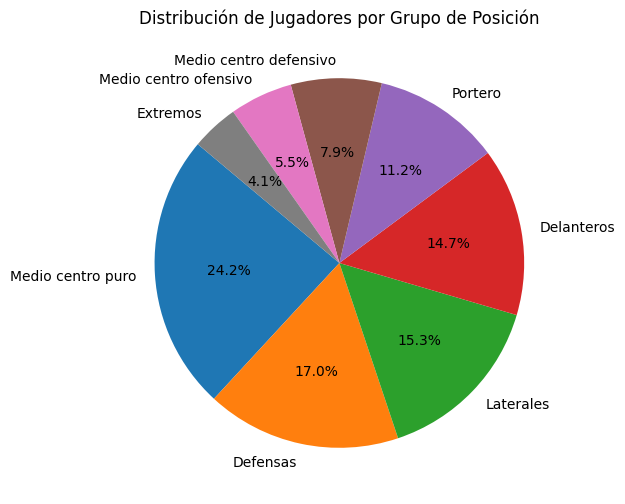

In [18]:
# Mapeo detallado a las 8 categorías específicas
position_mapping = {
    # Portero
    'GK': 'Portero',

    # Defensas (Centrales)
    'CB': 'Defensas',
    'RCB': 'Defensas',
    'LCB': 'Defensas',

    # Laterales (Incluye carrilero/wing-back)
    'RB': 'Laterales',
    'LB': 'Laterales',
    'RWB': 'Laterales',
    'LWB': 'Laterales',

    # Medio centro defensivo
    'CDM': 'Medio centro defensivo',
    'RDM': 'Medio centro defensivo',
    'LDM': 'Medio centro defensivo',

    # Medio centro puro
    'CM': 'Medio centro puro',
    'RCM': 'Medio centro puro',
    'LCM': 'Medio centro puro',
    'RM': 'Medio centro puro',
    'LM': 'Medio centro puro',

    # Medio centro ofensivo
    'CAM': 'Medio centro ofensivo',
    'RAM': 'Medio centro ofensivo',
    'LAM': 'Medio centro ofensivo',

    # Extremos
    'RW': 'Extremos',
    'LW': 'Extremos',

    # Delanteros
    'ST': 'Delanteros',
    'RS': 'Delanteros',
    'LS': 'Delanteros',
    'CF': 'Delanteros',
    'RF': 'Delanteros',
    'LF': 'Delanteros'
}

# 1. Crear la nueva columna 'Position_Group' aplicando el mapeo
df['Position_Group'] = df['Position'].map(position_mapping)

# 2. Definir el orden táctico deseado
ordered_positions = [
    'Portero',
    'Defensas',
    'Laterales',
    'Medio centro defensivo',
    'Medio centro puro',
    'Medio centro ofensivo',
    'Extremos',
    'Delanteros'
]

# 3. Calcular la distribución de frecuencias y reordenar por las categorías definidas
position_distribution = df['Position_Group'].value_counts()
ordered_distribution = position_distribution.reindex(ordered_positions).fillna(0).astype(int)

# 4. Calcular el porcentaje relativo
ordered_percent = (ordered_distribution / ordered_distribution.sum()) * 100

# 5. Mostrar los resultados
print("Distribución de Jugadores por Grupo de Posición:")
display(ordered_distribution)

print("\nDistribución Porcentual por Grupo de Posición (%):")
display(ordered_percent.round(2))

# Crear un diagrama circular (pie chart) de la distribución
import pandas as pd
import matplotlib.pyplot as plt

# Configurar el tamaño del gráfico
plt.figure(figsize=(10, 6))

# Crear el gráfico circular
ax = df['Position_Group'].value_counts().plot.pie(
    labels=position_distribution.index,
    autopct='%1.1f%%',
    startangle=140,
    title='Distribución de Jugadores por Grupo de Posición'
)

# Asegurarse de que el gráfico esté bien formateado
plt.ylabel('')
plt.show()

## Perfilar

Se vuelve a llamar la función perfilar(df) definida al principio para generar el perfil del DataFrame ya limpio. Con esto se confirma:

* Que Value, Wage y Release Clause quedaron como float64.
* Que Height_cm y Weight_lbs son numéricas.
* Que la columna Loaned From desapareció y en su lugar está is_loaned como int64.
* Que las columnas categóricas ya no tienen nulos.

In [19]:
perfilar(df)

,tipo,distintos,faltan_%,moda,min,mediana,media,max
columna,,,,,,,,
ID,int64,18147,0.0,16,16.00,221740.00,214279.82,2.466200e+05
Name,object,17140,0.0,J. Rodríguez,NaN,NaN,NaN,NaN
Age,int64,29,0.0,21,16.00,25.00,25.12,4.500000e+01
Nationality,object,164,0.0,England,NaN,NaN,NaN,NaN
Overall,int64,48,0.0,66,46.00,66.00,66.25,9.400000e+01
Potential,int64,47,0.0,70,48.00,71.00,71.32,9.500000e+01
Club,object,652,0.0,Sin club,NaN,NaN,NaN,NaN
Value,float64,217,0.0,1100000.0,0.00,675000.00,2417729.10,1.185000e+08
Wage,float64,144,0.0,1000.0,0.00,3000.00,9759.02,5.650000e+05


### Variables para value

Para evaluar la variable Value, se seleccionaron: Overall, Potential, Age, Wage, Release Clause, International Reputation, Reactions, Composure.

### Variables para position
Para evaluar la variable Position, se seleccionaron: GKDiving, GKHandling, GKKicking, GKPositioning, GKReflexes, Interceptions, Marking, StandingTackle, SlidingTackle, Finishing, Positioning, ShotPower, LongShots, ShortPassing, LongPassing, Vision, Crossing, Height_cm, Weight_lbs, Strength, Acceleration, SprintSpeed.

In [20]:
variables_cateogricas = [
    'Name', 'Nationality', 'Club', 'Preferred Foot', 'Work Rate',
    'Body Type', 'Position', 'Joined', 'Contract Valid Until','International Reputation',
]

variables_numericas = [
    'ID', 'Age', 'Overall', 'Potential', 'Value', 'Wage',
    'Weak Foot', 'Skill Moves', 'Jersey Number',
    'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys',
    'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl',
    'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance',
    'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots',
    'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties',
    'Composure', 'Marking', 'StandingTackle', 'SlidingTackle', 'GKDiving',
    'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes', 'Release Clause',
    'is_loaned', 'Height_cm', 'Weight_lbs'
]

In [21]:
# Variables numéricas clave para modelar Value y Position
columnas_importantes_value = [
    # Relevantes para Value (Target Numérico)
    'Overall', 'Potential', 'Age', 'Wage', 'Release Clause',
    'International Reputation', 'Reactions', 'Composure',
]
columnas_importantes_position = [
    # Relevantes para Position (Target Categórico)
    'GKDiving', 'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes',
    'Interceptions', 'Marking', 'StandingTackle', 'SlidingTackle',
    'Finishing', 'Positioning', 'ShotPower', 'LongShots',
    'ShortPassing', 'LongPassing', 'Vision', 'Crossing',
    'Height_cm', 'Weight_lbs', 'Strength', 'Acceleration', 'SprintSpeed'
]

# Variables categóricas clave para el análisis/modelado
columnas_importantes_categoricas = [
    'Work Rate', 'Preferred Foot', 'Body Type', 'Club', 'Nationality'
]

# EDA con el codigo/libreria generico de internet

In [22]:
#eda_basico = ProfileReport(df, title="Reporte de EDA Básico")
#eda_basico.to_notebook_iframe()
#eda_basico.to_file("reporte_eda.html")

In [23]:
df_todo = df.copy()

# Parte · Regresión lineal: ¿qué aporta más valor, las estadísticas o la carrera?

## 1. El caso y la métrica — escritos antes

Un club quiere una **primera estimación del valor de mercado** de un jugador antes de que la revise un analista. El valor lo fija el mercado; el modelo dice por dónde empezar. De paso responde la pregunta de fondo: **¿pesa más lo que el jugador hace en la cancha (sus estadísticas) o lo que lo rodea (edad, reputación, salario, contrato)?**

**Métrica que manda: el error absoluto medio (MAE), en euros.** Es lo que entiende la gerencia: «el modelo se equivoca, en promedio, en tantos euros». Al lado se reportan:

* **RMSE:** castiga más los errores grandes (equivocarse en 20 M en una estrella pesa).
* **R²:** qué parte de las diferencias de valor explica el modelo.
* **Error relativo mediano** y **% de jugadores con error mayor a 30 %:** los valores van de decenas de miles a más de 100 millones de euros, y un error de 1 M no significa lo mismo en un suplente que en una estrella. El umbral de 30 % lo fija el grupo.

**Cómo se compara.** Todo con validación cruzada de 5 folds sobre el 80 % de entrenamiento. El 20 % de prueba se aparta en la sección 3 y no se toca hasta la sección 8.

**Regla de decisión, escrita antes.** Entre el modelo con el valor en euros y el modelo con el valor en logaritmo se escoge el de menor MAE de validación. Si la diferencia es menor a 3 %, se escoge el de logaritmo, porque nunca predice valores negativos.

In [45]:
from IPython.display import Markdown, display
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.dummy import DummyRegressor
from sklearn.feature_selection import SelectFromModel
from sklearn.model_selection import (train_test_split, KFold, StratifiedKFold, cross_validate,
                                     cross_val_score, cross_val_predict, GridSearchCV)
from sklearn.metrics import (make_scorer, mean_absolute_error, mean_squared_error, r2_score,
                             roc_auc_score, accuracy_score, classification_report, confusion_matrix)
SEMILLA = 2026
def md(texto):
    """Muestra texto como Markdown (los 'qué veo' se arman con los números reales)."""
    display(Markdown(texto))

## 2. Perfilar el objetivo: `Value` y sus ceros

Antes de modelar se mira el objetivo (como en S17, sección 2): su forma y, sobre todo, si todos sus valores son realmente un precio.

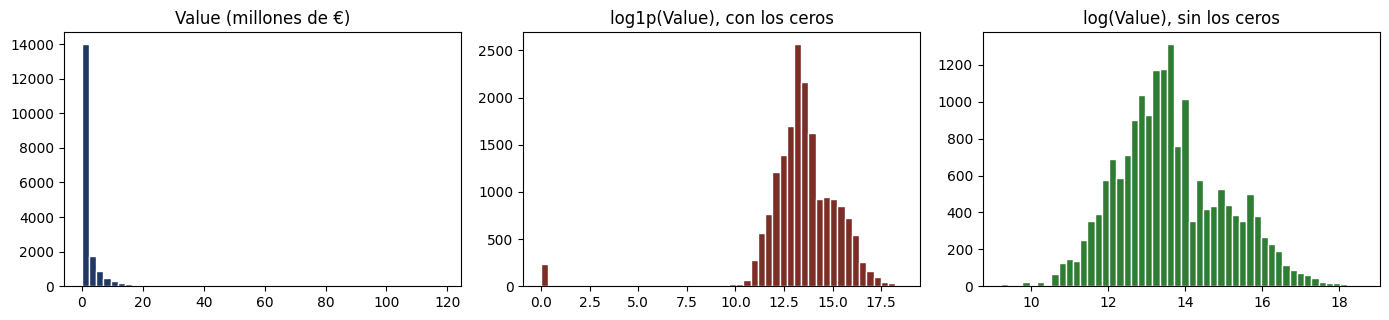

**Qué veo.** 240 jugadores (1.3 %) tienen `Value = 0`; el 95.4 % está «Sin club» y el 95.4 % tiene `Wage = 0`. Su `Overall` mediano es 68 (el de todos los jugadores: 66). La asimetría de `Value` es 7.06; la de `log1p(Value)` con los ceros, -3.28; la de `log(Value)` sin los ceros, 0.38.

In [46]:
# El df limpio no se modifica: se trabaja sobre una copia
datos_fifa = df.copy()
if not pd.api.types.is_numeric_dtype(datos_fifa["Preferred Foot"]):
    datos_fifa["Preferred Foot"] = datos_fifa["Preferred Foot"].map({"Right": 1, "Left": 0})

ceros = datos_fifa[datos_fifa["Value"] == 0]
con_valor = datos_fifa[datos_fifa["Value"] > 0]
asim = lambda s: float(s.skew())

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].hist(datos_fifa["Value"] / 1e6, bins=50, color="#1f3864", edgecolor="white"); ax[0].set_title("Value (millones de €)")
ax[1].hist(np.log1p(datos_fifa["Value"]), bins=50, color="#7b2d26", edgecolor="white"); ax[1].set_title("log1p(Value), con los ceros")
ax[2].hist(np.log(con_valor["Value"]), bins=50, color="#2e7d32", edgecolor="white"); ax[2].set_title("log(Value), sin los ceros")
plt.tight_layout(); plt.show()

md(f"""**Qué veo.** {len(ceros)} jugadores ({100 * len(ceros) / len(datos_fifa):.1f} %) tienen `Value = 0`; el {100 * (ceros['Club'] == 'Sin club').mean():.1f} % está «Sin club» y el {100 * (ceros['Wage'] == 0).mean():.1f} % tiene `Wage = 0`. Su `Overall` mediano es {ceros['Overall'].median():.0f} (el de todos los jugadores: {datos_fifa['Overall'].median():.0f}). La asimetría de `Value` es {asim(datos_fifa['Value']):.2f}; la de `log1p(Value)` con los ceros, {asim(np.log1p(datos_fifa['Value'])):.2f}; la de `log(Value)` sin los ceros, {asim(np.log(con_valor['Value'])):.2f}.""")

In [47]:
df_lin = con_valor.copy()
df_lin["Wage_log"] = np.log1p(df_lin["Wage"])          # salario muy asimétrico: se usa en logaritmo
df_lin["Contract_year"] = pd.to_numeric(                # año en que vence el contrato ("No disponible" queda vacío)
    df_lin["Contract Valid Until"].astype(str).str.extract(r"(\d{4})")[0], errors="coerce")

md(f"""**Qué decido.** Esos {len(ceros)} jugadores salen de los modelos de `Value` (siguen en `df`). Quedan **{len(df_lin):,}** jugadores y un objetivo en logaritmo casi simétrico. Se crean dos columnas: `Wage_log` (el salario en logaritmo) y `Contract_year` (el año de vencimiento del contrato; queda vacío en {int(df_lin['Contract_year'].isna().sum())} jugadores y el `Pipeline` lo rellena con la mediana).""")

**Qué decido.** Esos 240 jugadores salen de los modelos de `Value` (siguen en `df`). Quedan **17,907** jugadores y un objetivo en logaritmo casi simétrico. Se crean dos columnas: `Wage_log` (el salario en logaritmo) y `Contract_year` (el año de vencimiento del contrato; queda vacío en 0 jugadores y el `Pipeline` lo rellena con la mediana).

## 3. La partición y los bloques de variables

La pregunta compara dos mundos, así que las variables se agrupan en **bloques**:

| Bloque | Qué contiene |
|---|---|
| **Estadísticas** | los atributos de juego (pases, tiro, defensa, portero…), altura, peso, pie preferido, pie malo, filigranas y el rol (`Position_Group`, `Work Rate`, `Body Type`) |
| **Resumen de calidad** | `Overall` y `Potential`. Sintetizan las estadísticas, por eso se prueban aparte: así no esconden al bloque de estadísticas detrás de ellas |
| **Carrera** | `Age`, `International Reputation`, `is_loaned`, `Wage_log` y `Contract_year` |

**Decisiones sobre variables**

* `Release Clause` **no entra** (sección 4).
* `ID`, `Name` y `Joined` (identificadores o casi únicos), `Jersey Number` (el dorsal no describe al jugador), `Club` (cientos de categorías) y `Position` (redundante con `Position_Group`) quedan fuera.
* `Contract Valid Until` **no** es casi única (tiene pocos años distintos), así que no se elimina: se convierte en el número `Contract_year`.
* `Nationality` queda fuera de esta comparación: no es ni estadística ni carrera, y agruparla por debajo de 5 % dejaba al 68 % de los jugadores en «Otros».
* Las categóricas usan `OneHotEncoder(drop="first")`. Con todas las columnas 0/1 de una variable, su suma siempre es 1, igual que la constante del modelo: los coeficientes dejan de tener una lectura única (la «trampa de las variables ficticias»). Al omitir una categoría, cada coeficiente se lee **frente a esa categoría base**.
* Las numéricas se imputan con la mediana y se estandarizan **dentro del `Pipeline`**. Estandarizar las X no cambia la predicción de una regresión lineal, pero deja cada coeficiente como «efecto de +1 desviación estándar», que **sí** es comparable entre variables.

In [48]:
ATRIBUTOS = ["Crossing", "Finishing", "HeadingAccuracy", "ShortPassing", "Volleys", "Dribbling", "Curve", "FKAccuracy",
             "LongPassing", "BallControl", "Acceleration", "SprintSpeed", "Agility", "Reactions", "Balance", "ShotPower",
             "Jumping", "Stamina", "Strength", "LongShots", "Aggression", "Interceptions", "Positioning", "Vision",
             "Penalties", "Composure", "Marking", "StandingTackle", "SlidingTackle", "GKDiving", "GKHandling",
             "GKKicking", "GKPositioning", "GKReflexes"]
PERFIL_NUM = ["Preferred Foot", "Weak Foot", "Skill Moves", "Height_cm", "Weight_lbs"]
ROL_CAT    = ["Position_Group", "Work Rate", "Body Type"]
RESUMEN    = ["Overall", "Potential"]
CARRERA    = ["Age", "International Reputation", "is_loaned", "Wage_log", "Contract_year"]

faltan = [c for c in ATRIBUTOS + PERFIL_NUM + ROL_CAT + RESUMEN + CARRERA if c not in df_lin.columns]
assert not faltan, f"Faltan columnas en df: {faltan}"

ESTAD_NUM = ATRIBUTOS + PERFIL_NUM
NUM_TODO, CAT_TODO = ESTAD_NUM + RESUMEN + CARRERA, ROL_CAT
COLS_TODO = NUM_TODO + CAT_TODO

# La prueba se aparta AHORA y no se toca hasta la sección 8
idx_tr_lin, idx_te_lin = train_test_split(df_lin.index, test_size=0.2, random_state=SEMILLA)
D_tr, D_te = df_lin.loc[idx_tr_lin], df_lin.loc[idx_te_lin]
yl_tr, yl_te = D_tr["Value"], D_te["Value"]
print("Entrenamiento:", len(D_tr), "| Prueba:", len(D_te))
print(f"Variables: {len(ESTAD_NUM)} numéricas de estadísticas + {len(ROL_CAT)} categóricas de rol | {len(RESUMEN)} de resumen | {len(CARRERA)} de carrera")

# ---------- funciones que se usan en todo el análisis ----------
UMBRAL_ERR = 0.30
def err_rel_mediano(y, p): return np.median(np.abs(y - p) / y)
def pct_err_alto(y, p):    return np.mean(np.abs(y - p) / y > UMBRAL_ERR)

METRICAS_LIN = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2",
            "ERM": make_scorer(err_rel_mediano, greater_is_better=False),
            "E30": make_scorer(pct_err_alto, greater_is_better=False)}
kf_lin = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)

def lin_construir(nums, cats, log=True):
    """Regresión lineal dentro de un Pipeline. Con log=True el valor se modela en logaritmo y se predice en euros."""
    partes = []
    if nums: partes.append(("num", Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]), nums))
    if cats: partes.append(("cat", OneHotEncoder(drop="first", handle_unknown="ignore"), cats))
    pipe = Pipeline([("prep", ColumnTransformer(partes)), ("lineal", LinearRegression())])
    return TransformedTargetRegressor(regressor=pipe, func=np.log, inverse_func=np.exp) if log else pipe

def lin_medir(modelo, nums, cats):
    """Validación cruzada de 5 folds SOLO sobre el entrenamiento; las métricas salen en euros."""
    r = cross_validate(modelo, D_tr[nums + cats], yl_tr, cv=kf_lin, scoring=METRICAS_LIN)
    return {"MAE (€)": -r["test_MAE"].mean(), "RMSE (€)": -r["test_RMSE"].mean(), "R²": r["test_R2"].mean(),
            "R² desv": r["test_R2"].std(), "ERM": -r["test_ERM"].mean(), "E30": -r["test_E30"].mean()}

def lin_mostrar(tabla):
    t = pd.DataFrame(index=tabla.index)
    t["MAE (€)"] = tabla["MAE (€)"].map("{:,.0f}".format)
    t["RMSE (€)"] = tabla["RMSE (€)"].map("{:,.0f}".format)
    t["R²"] = [f"{a:.3f} ± {b:.3f}" for a, b in zip(tabla["R²"], tabla["R² desv"])]
    t["error relativo mediano"] = (100 * tabla["ERM"]).map("{:.1f} %".format)
    t["% con error > 30 %"] = (100 * tabla["E30"]).map("{:.1f} %".format)
    return t

Entrenamiento: 14325 | Prueba: 3582
Variables: 39 numéricas de estadísticas + 3 categóricas de rol | 2 de resumen | 5 de carrera


## 4. La variable que no se puede usar: `Release Clause`

En el primer intento el R² fue de 0.96 y la conclusión fue «precisión excepcional». Esa cifra venía de `Release Clause` (la cláusula de rescisión), que en el juego se deriva del valor del jugador: es casi el objetivo con otro nombre. Hay que mirar dos cosas:

1. Su correlación con `Value`.
2. El **0** que toma en los jugadores cedidos. No es «una cláusula de 0 €»: es «sin cláusula». Es el mismo caso del `−1` de `pdays` en S18.

**Ojo con la prueba que se hizo antes.** Una brecha pequeña entre entrenamiento y prueba, y una validación cruzada estable, **no detectan una fuga**: la cláusula está igual de «filtrada» en el entrenamiento, en la prueba y en cada fold. Una fuga se detecta razonando de dónde sale la variable.

In [49]:
sin_clausula = df_lin["Release Clause"] == 0
coinciden = (sin_clausula == (df_lin["is_loaned"] == 1)).mean()
corr_rc = df_lin["Value"].corr(df_lin["Release Clause"])
corr_wage = df_lin["Value"].corr(df_lin["Wage"])

# Con y sin la cláusula, en euros (el objetivo de esta comparación es lin_mostrar la fuga, no escoger modelo)
COLS_RC = NUM_TODO + ["Release Clause"]
res_rc = {"SIN Release Clause": lin_medir(lin_construir(NUM_TODO, CAT_TODO, log=False), NUM_TODO, CAT_TODO),
          "CON Release Clause (fuga)": lin_medir(lin_construir(COLS_RC, CAT_TODO, log=False), COLS_RC, CAT_TODO)}
display(lin_mostrar(pd.DataFrame(res_rc).T))

def coef_cedido(cols):
    X = D_tr[cols]; X = X.fillna(X.median())
    return LinearRegression().fit(X, yl_tr).coef_[cols.index("is_loaned")]
b_sin, b_con = coef_cedido(NUM_TODO), coef_cedido(COLS_RC)

md(f"""**Qué veo.** La correlación de `Release Clause` con `Value` es {corr_rc:.3f} (la del salario, {corr_wage:.3f}). Con la cláusula el R² de validación es {res_rc['CON Release Clause (fuga)']['R²']:.3f}; sin ella, {res_rc['SIN Release Clause']['R²']:.3f}. Además, `Release Clause = 0` y `is_loaned = 1` coinciden fila a fila en el {100 * coinciden:.1f} % de los jugadores. El coeficiente de `is_loaned` es {b_con:+,.0f} € con la cláusula y {b_sin:+,.0f} € sin ella.""")

,MAE (€),RMSE (€),R²,error relativo mediano,% con error > 30 %
SIN Release Clause,"1,809,975","3,462,629",0.629 ± 0.019,125.0 %,81.6 %
CON Release Clause (fuga),"490,268","1,195,939",0.955 ± 0.018,25.4 %,45.1 %


**Qué veo.** La correlación de `Release Clause` con `Value` es 0.967 (la del salario, 0.858). Con la cláusula el R² de validación es 0.955; sin ella, 0.629. Además, `Release Clause = 0` y `is_loaned = 1` coinciden fila a fila en el 100.0 % de los jugadores. El coeficiente de `is_loaned` es +2,010,762 € con la cláusula y -716,558 € sin ella.

In [50]:
cambia_signo = np.sign(b_con) != np.sign(b_sin)
frase_signo = ("sin la cláusula, el signo cambia" if cambia_signo else "sin la cláusula, el coeficiente cambia de tamaño")
md(f"""**Qué significa.** El R² «excelente» con la cláusula no es mérito del modelo: es la misma información del objetivo entrando por otra columna. Y como los cedidos tienen `Release Clause = 0`, el modelo usa `is_loaned` para corregir ese 0: el coeficiente de `is_loaned` con la cláusula es un **artefacto**, no el efecto de «estar cedido» ({frase_signo}). Por eso la conclusión del primer intento («estar en préstamo eleva el valor en +1.78 M €, porque pertenecen a clubes de élite») era un error de lectura.

**Qué decido.** `Release Clause` sale del modelo. El salario (`Wage`) **sí se queda**, y queda escrito como decisión: la pregunta es qué aporta al valor la carrera del jugador, y el contrato actual es parte de esa carrera. Pero el salario también se mueve junto con el valor, así que en la sección 5 se mide cuánto cambia el resultado **con y sin él**.""")

**Qué significa.** El R² «excelente» con la cláusula no es mérito del modelo: es la misma información del objetivo entrando por otra columna. Y como los cedidos tienen `Release Clause = 0`, el modelo usa `is_loaned` para corregir ese 0: el coeficiente de `is_loaned` con la cláusula es un **artefacto**, no el efecto de «estar cedido» (sin la cláusula, el signo cambia). Por eso la conclusión del primer intento («estar en préstamo eleva el valor en +1.78 M €, porque pertenecen a clubes de élite») era un error de lectura.

**Qué decido.** `Release Clause` sale del modelo. El salario (`Wage`) **sí se queda**, y queda escrito como decisión: la pregunta es qué aporta al valor la carrera del jugador, y el contrato actual es parte de esa carrera. Pero el salario también se mueve junto con el valor, así que en la sección 5 se mide cuánto cambia el resultado **con y sin él**.

## 5. Estadísticas contra carrera: los modelos por bloques

La pregunta («¿qué aporta más valor?») no se contesta mirando coeficientes sueltos: se contesta **comparando modelos que usan un bloque u otro**. Todos son regresiones lineales con la misma partición y la misma validación cruzada. El valor se modela en logaritmo, como en S17, salvo en la última fila, que lo deja en euros para poder comparar.

In [51]:
CONFIG = [
    ("base",      "Línea base: predecir siempre la mediana",   DummyRegressor(strategy="median"), ["Age"], []),
    ("estad",     "Solo estadísticas",                         lin_construir(ESTAD_NUM, ROL_CAT), ESTAD_NUM, ROL_CAT),
    ("estad_res", "Estadísticas + Overall y Potential",        lin_construir(ESTAD_NUM + RESUMEN, ROL_CAT), ESTAD_NUM + RESUMEN, ROL_CAT),
    ("carrera",   "Solo carrera",                              lin_construir(CARRERA, []), CARRERA, []),
    ("car_sin_w", "Solo carrera, sin el salario",             lin_construir([c for c in CARRERA if c != "Wage_log"], []), [c for c in CARRERA if c != "Wage_log"], []),
    ("est_car",   "Estadísticas + carrera",                    lin_construir(ESTAD_NUM + CARRERA, ROL_CAT), ESTAD_NUM + CARRERA, ROL_CAT),
    ("todo_log",  "Todo (valor en logaritmo)",                 lin_construir(NUM_TODO, CAT_TODO), NUM_TODO, CAT_TODO),
    ("sin_wage",  "Todo menos el salario (logaritmo)",         lin_construir([c for c in NUM_TODO if c != "Wage_log"], CAT_TODO),
                                                               [c for c in NUM_TODO if c != "Wage_log"], CAT_TODO),
    ("todo_eur",  "Todo (valor en euros, sin logaritmo)",      lin_construir(NUM_TODO, CAT_TODO, log=False), NUM_TODO, CAT_TODO),
]
res = {clave: lin_medir(m, n, c) for clave, _, m, n, c in CONFIG}
tabla = pd.DataFrame(res).T
tabla.index = [etiqueta for _, etiqueta, *_ in CONFIG]
display(lin_mostrar(tabla))

r2 = lambda k: res[k]["R²"]
mae = lambda k: res[k]["MAE (€)"]
mejor_bloque = "las estadísticas" if r2("estad") > r2("carrera") else "la carrera"
verbo = "explican" if r2("estad") > r2("carrera") else "explica"
otro_bloque = "la carrera" if r2("estad") > r2("carrera") else "las estadísticas"
r2_ganador, r2_perdedor = max(r2("estad"), r2("carrera")), min(r2("estad"), r2("carrera"))

md(f"""**Qué veo.** Por separado, las estadísticas llegan a R² = {r2('estad'):.3f} y la carrera a {r2('carrera'):.3f} (predecir siempre la mediana da {r2('base'):.3f}). Juntas llegan a {r2('est_car'):.3f}, y con `Overall` y `Potential`, a {r2('todo_log'):.3f}. Sin el salario, la carrera sola baja a {r2('car_sin_w'):.3f} y el modelo completo, a {r2('sin_wage'):.3f}. Con el valor en euros, el MAE es de {mae('todo_eur'):,.0f} €; con el valor en logaritmo, de {mae('todo_log'):,.0f} €.""")

,MAE (€),RMSE (€),R²,error relativo mediano,% con error > 30 %
Línea base: predecir siempre la mediana,"2,106,742","5,947,644",-0.095 ± 0.010,75.8 %,77.1 %
Solo estadísticas,"1,108,454","3,266,086",0.671 ± 0.026,37.8 %,60.0 %
Estadísticas + Overall y Potential,"573,799","3,079,360",0.684 ± 0.224,15.2 %,19.6 %
Solo carrera,"1,130,460","3,123,805",0.694 ± 0.065,45.6 %,66.9 %
"Solo carrera, sin el salario","1,893,297","7,336,801",-0.750 ± 0.997,68.5 %,77.9 %
Estadísticas + carrera,"879,307","4,367,996",0.278 ± 0.725,30.2 %,50.4 %
Todo (valor en logaritmo),"507,743","2,765,698",0.751 ± 0.130,13.2 %,14.5 %
Todo menos el salario (logaritmo),"510,579","2,816,794",0.738 ± 0.154,13.9 %,15.2 %
"Todo (valor en euros, sin logaritmo)","1,809,975","3,462,629",0.629 ± 0.019,125.0 %,81.6 %


**Qué veo.** Por separado, las estadísticas llegan a R² = 0.671 y la carrera a 0.694 (predecir siempre la mediana da -0.095). Juntas llegan a 0.278, y con `Overall` y `Potential`, a 0.751. Sin el salario, la carrera sola baja a -0.750 y el modelo completo, a 0.738. Con el valor en euros, el MAE es de 1,809,975 €; con el valor en logaritmo, de 507,743 €.

In [52]:
caida_wage = r2("todo_log") - r2("sin_wage")
frase_wage = (f"Quitar el salario le cuesta {caida_wage:.3f} de R² al modelo completo: buena parte del «poder de la carrera» es el salario, que se mueve junto con el valor porque ambos los fija el mismo mercado. No se lee como causa."
              if caida_wage > 0.02 else
              f"Quitar el salario casi no cambia el resultado (solo {caida_wage:.3f} de R²), así que la conclusión no depende de esa decisión.")
subida_res = r2("estad_res") - r2("estad")

FINAL_LOG = mae("todo_log") <= 1.03 * mae("todo_eur")        # la regla escrita en la sección 1
ERM_log, ERM_eur = res["todo_log"]["ERM"], res["todo_eur"]["ERM"]
nota_rel = ("" if (ERM_log < ERM_eur) == FINAL_LOG else
            f" Ojo: por error relativo mediano gana el otro ({100 * ERM_log:.1f} % con logaritmo contra {100 * ERM_eur:.1f} % con euros); se deja dicho, y se sigue la regla escrita antes.")

md(f"""**Qué significa.** Tomadas por separado, **{mejor_bloque}** {verbo} más del valor (R² {r2_ganador:.3f} contra {r2_perdedor:.3f} de {otro_bloque}), y juntas explican más que cualquiera de las dos: los bloques se complementan. Añadir `Overall` y `Potential` a las estadísticas sube el R² en {subida_res:.3f}: ese resumen de calidad aporta información que los atributos sueltos no capturan bien. {frase_wage}

**Qué decido.** Para predecir se usa el modelo completo **{'con el valor en logaritmo' if FINAL_LOG else 'con el valor en euros'}**: {'tiene el menor MAE de validación o queda a menos de 3 % del de euros (regla de la sección 1)' if FINAL_LOG else 'su MAE de validación es más de 3 % menor que el del logaritmo'}.{nota_rel} Falta confirmar con los residuos si esa forma del modelo está bien planteada.""")

**Qué significa.** Tomadas por separado, **la carrera** explica más del valor (R² 0.694 contra 0.671 de las estadísticas), y juntas explican más que cualquiera de las dos: los bloques se complementan. Añadir `Overall` y `Potential` a las estadísticas sube el R² en 0.014: ese resumen de calidad aporta información que los atributos sueltos no capturan bien. Quitar el salario casi no cambia el resultado (solo 0.013 de R²), así que la conclusión no depende de esa decisión.

**Qué decido.** Para predecir se usa el modelo completo **con el valor en logaritmo**: tiene el menor MAE de validación o queda a menos de 3 % del de euros (regla de la sección 1). Falta confirmar con los residuos si esa forma del modelo está bien planteada.

## 6. Los residuos: lo que el modelo no explica

Un residuo es **valor real − valor predicho**. Si el modelo está bien planteado, los residuos no tienen forma: una nube pareja alrededor de cero. Si la nube se abre como un embudo, el error crece con el valor y el modelo está mal planteado (S17, sección 5). Los residuos se calculan con validación cruzada, es decir, sin tocar la prueba.

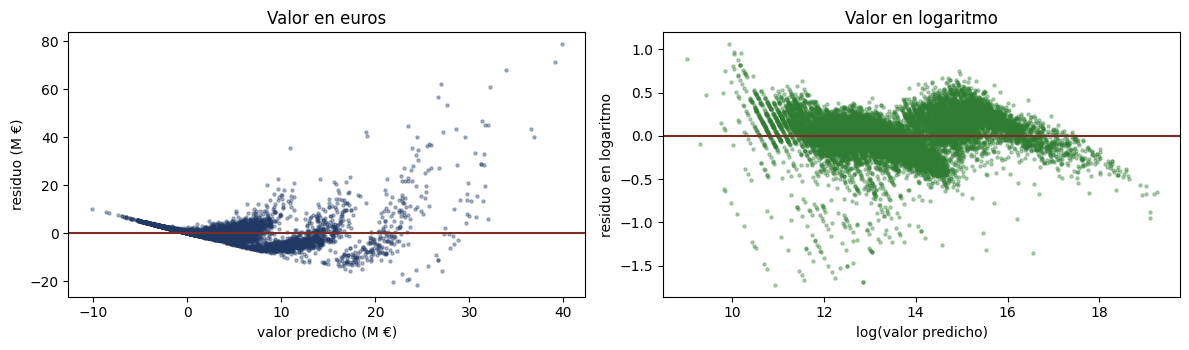

**Qué veo.** Con el valor en euros, el residuo se dispersa 3.8 veces más en los jugadores que el modelo predice caros que en los que predice baratos; con el valor en logaritmo, 1.0 veces. Además, el modelo en euros predice **valores negativos** para el 27.6 % de los jugadores.

In [53]:
pred_eur = cross_val_predict(lin_construir(NUM_TODO, CAT_TODO, log=False), D_tr[COLS_TODO], yl_tr, cv=kf_lin)
pred_log = cross_val_predict(lin_construir(NUM_TODO, CAT_TODO, log=True),  D_tr[COLS_TODO], yl_tr, cv=kf_lin)
res_eur = (yl_tr.values - pred_eur) / 1e6                       # millones de €
res_log = np.log(yl_tr.values) - np.log(pred_log)               # diferencia en logaritmo ≈ error en %

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].scatter(pred_eur / 1e6, res_eur, s=5, alpha=.35, color="#1f3864"); ax[0].axhline(0, color="#7b2d26")
ax[0].set_title("Valor en euros"); ax[0].set_xlabel("valor predicho (M €)"); ax[0].set_ylabel("residuo (M €)")
ax[1].scatter(np.log(pred_log), res_log, s=5, alpha=.35, color="#2e7d32"); ax[1].axhline(0, color="#7b2d26")
ax[1].set_title("Valor en logaritmo"); ax[1].set_xlabel("log(valor predicho)"); ax[1].set_ylabel("residuo en logaritmo")
plt.tight_layout(); plt.show()

def embudo(pred, resid):
    bajo = pred < np.median(pred)
    return np.std(resid[~bajo]) / np.std(resid[bajo])
emb_eur, emb_log = embudo(pred_eur, res_eur), embudo(pred_log, res_log)
neg = 100 * (pred_eur < 0).mean()

md(f"""**Qué veo.** Con el valor en euros, el residuo se dispersa {emb_eur:.1f} veces más en los jugadores que el modelo predice caros que en los que predice baratos; con el valor en logaritmo, {emb_log:.1f} veces. Además, el modelo en euros predice **valores negativos** para el {neg:.1f} % de los jugadores.""")

In [54]:
md(f"""**Qué significa.** {'La nube en euros tiene forma de embudo: el error crece con el valor, así que ese modelo está mal planteado. ' if emb_eur > 1.5 else 'La dispersión en euros crece con el valor, aunque menos de lo esperado. '}Un valor negativo no existe: es el equivalente de las «probabilidades» fuera de [0, 1] de la regresión lineal en S18. Con el logaritmo el error se mide en porcentaje y la predicción siempre es positiva.

**Qué decido.** {'Se confirma el modelo en logaritmo como final: ' if FINAL_LOG else 'Se mantiene el modelo en euros como final porque la regla de la sección 1 lo indica, pero queda anotado el embudo y los valores negativos como límite: '}{'es el que mejor se comporta en residuos y cumple la regla de MAE.' if FINAL_LOG else 'su error no es parejo entre jugadores baratos y caros.'}""")

**Qué significa.** La nube en euros tiene forma de embudo: el error crece con el valor, así que ese modelo está mal planteado. Un valor negativo no existe: es el equivalente de las «probabilidades» fuera de [0, 1] de la regresión lineal en S18. Con el logaritmo el error se mide en porcentaje y la predicción siempre es positiva.

**Qué decido.** Se confirma el modelo en logaritmo como final: es el que mejor se comporta en residuos y cumple la regla de MAE.

## 7. Leer los coeficientes

Se ajusta el modelo final **solo con el entrenamiento**. Como las variables numéricas están estandarizadas, cada coeficiente es el efecto de **+1 desviación estándar** de esa variable, **con todo lo demás igual**, y por eso se pueden comparar entre variables. Con el valor en logaritmo, cada coeficiente se lee como un porcentaje.

In [55]:
FINAL = lin_construir(NUM_TODO, CAT_TODO, log=FINAL_LOG).fit(D_tr[COLS_TODO], yl_tr)
pipe = FINAL.regressor_ if FINAL_LOG else FINAL
prep, coef = pipe.named_steps["prep"], pipe.named_steps["lineal"].coef_
nombres_raw = list(prep.get_feature_names_out())
coefs = pd.DataFrame({"variable": [n.split("__", 1)[1] for n in nombres_raw],
                      "es_num": [n.startswith("num__") for n in nombres_raw], "coef": coef})
coefs["efecto"] = (np.exp(coefs["coef"]) - 1) * 100 if FINAL_LOG else coefs["coef"]
coefs["abs"] = coefs["efecto"].abs()
UNIDAD = "% de cambio en el valor por +1 desviación estándar" if FINAL_LOG else "€ por +1 desviación estándar"
bloque = lambda v: "carrera" if v in CARRERA else ("resumen" if v in RESUMEN else "estadística")

tab_num = coefs[coefs["es_num"]].sort_values("abs", ascending=False).head(12).copy()
tab_num["bloque"] = tab_num["variable"].map(bloque)
tab_num["efecto"] = tab_num["efecto"].round(1 if FINAL_LOG else 0)
print("Variables numéricas con mayor efecto:", UNIDAD)
display(tab_num[["variable", "bloque", "efecto"]].reset_index(drop=True))

bases = {c: cats[0] for c, cats in zip(CAT_TODO, prep.named_transformers_["cat"].categories_)}
tab_cat = coefs[~coefs["es_num"]].sort_values("abs", ascending=False).head(8).copy()
tab_cat["efecto"] = tab_cat["efecto"].round(1 if FINAL_LOG else 0)
print("\nCategóricas con mayor efecto, frente a la categoría base de cada variable:", bases)
display(tab_cat[["variable", "efecto"]].reset_index(drop=True))

f = (lambda x: f"{x:+.1f} %") if FINAL_LOG else (lambda x: f"{x:+,.0f} €")
t = tab_num.reset_index(drop=True)
md(f"""**Qué veo.** Las variables numéricas de mayor efecto son `{t.loc[0, 'variable']}` ({f(t.loc[0, 'efecto'])}), `{t.loc[1, 'variable']}` ({f(t.loc[1, 'efecto'])}) y `{t.loc[2, 'variable']}` ({f(t.loc[2, 'efecto'])}), por +1 desviación estándar. Del bloque de carrera hay {int((t['bloque'] == 'carrera').sum())} entre las 12 primeras; de estadísticas, {int((t['bloque'] == 'estadística').sum())}; de resumen, {int((t['bloque'] == 'resumen').sum())}.""")

Variables numéricas con mayor efecto: % de cambio en el valor por +1 desviación estándar


,variable,bloque,efecto
0,Overall,resumen,331.1
1,Age,carrera,-37.0
2,Wage_log,carrera,9.8
3,BallControl,estadística,-4.8
4,Potential,resumen,-3.1
5,Stamina,estadística,3.0
6,GKHandling,estadística,-3.0
7,GKPositioning,estadística,-2.9
8,GKDiving,estadística,2.7
9,GKKicking,estadística,-2.3



Categóricas con mayor efecto, frente a la categoría base de cada variable: {'Position_Group': 'Defensas', 'Work Rate': 'High/ High', 'Body Type': 'Lean'}


,variable,efecto
0,Position_Group_Medio centro ofensivo,17.2
1,Position_Group_Delanteros,16.2
2,Position_Group_Medio centro puro,13.2
3,Position_Group_Portero,11.7
4,Position_Group_Extremos,10.6
5,Work Rate_Low/ High,-5.4
6,Position_Group_Laterales,-5.0
7,Work Rate_Low/ Medium,-2.7


**Qué veo.** Las variables numéricas de mayor efecto son `Overall` (+331.1 %), `Age` (-37.0 %) y `Wage_log` (+9.8 %), por +1 desviación estándar. Del bloque de carrera hay 2 entre las 12 primeras; de estadísticas, 8; de resumen, 2.

**Qué significa.** Estos efectos son «con todo lo demás igual», y eso cambia la lectura de tres maneras:

* **Un coeficiente grande no es una causa.** `Wage_log` e `International Reputation` se mueven junto con el valor porque los fija el mismo mercado: subirle el salario a un jugador no le sube el valor.
* **Las categóricas se leen frente a su categoría base**, nunca frente al «promedio de todos». Si la base cambia, los números cambian (pero no la predicción).
* **Variables que dicen casi lo mismo se reparten el efecto**, como `GarageCars` y `GarageArea` en S17. Ninguna se lee sin mirar a la otra: la siguiente celda lo muestra con `Potential` y `Overall`.

### Dos variables que dicen casi lo mismo: `Potential` y `Overall`

En el primer intento `Potential` salía con **coeficiente negativo** (−27 mil € por punto con la cláusula y −39 mil € sin ella), aunque a mayor potencial hay mayor valor. Eso es colinealidad, y se comprueba como en S17 (sección 8): el coeficiente de `Potential` **solo** contra el coeficiente con `Overall` y `Age` **al lado**.

In [56]:
ly = np.log(yl_tr)
corr_po = D_tr["Potential"].corr(D_tr["Overall"])
corr_py = D_tr["Potential"].corr(ly)
solo = LinearRegression().fit(D_tr[["Potential"]], ly).coef_[0]
junto = LinearRegression().fit(D_tr[["Potential", "Overall", "Age"]], ly).coef_[0]
pct = lambda c: (np.exp(c) - 1) * 100

md(f"""**Qué veo.** `Potential` y `Overall` tienen una correlación de {corr_po:.2f}; `Potential` con el logaritmo del valor, {corr_py:.2f}. Un punto más de `Potential` **solo** cambia el valor en {pct(solo):+.1f} %; con `Overall` y `Age` al lado, en {pct(junto):+.1f} %.

**Qué significa.** {'El signo se invierte: ' if np.sign(solo) != np.sign(junto) else 'El coeficiente cambia de tamaño: '}`Potential` y `Overall` se reparten el efecto, porque dicen casi lo mismo. Con `Overall` ya en el modelo, el coeficiente de `Potential` mide solo lo que `Potential` agrega **por encima** de `Overall` (y a la misma edad), no «cuánto vale el potencial».

**Qué decido.** No se interpreta ningún coeficiente de `Potential`, `Overall` ni de los atributos muy correlacionados entre sí (`Reactions`, `Composure`, `BallControl`, `ShortPassing`…) por separado. Para eso están los modelos por bloques de la sección 5: comparan grupos de variables, no variables sueltas.""")

**Qué veo.** `Potential` y `Overall` tienen una correlación de 0.66; `Potential` con el logaritmo del valor, 0.79. Un punto más de `Potential` **solo** cambia el valor en +19.9 %; con `Overall` y `Age` al lado, en -0.8 %.

**Qué significa.** El signo se invierte: `Potential` y `Overall` se reparten el efecto, porque dicen casi lo mismo. Con `Overall` ya en el modelo, el coeficiente de `Potential` mide solo lo que `Potential` agrega **por encima** de `Overall` (y a la misma edad), no «cuánto vale el potencial».

**Qué decido.** No se interpreta ningún coeficiente de `Potential`, `Overall` ni de los atributos muy correlacionados entre sí (`Reactions`, `Composure`, `BallControl`, `ShortPassing`…) por separado. Para eso están los modelos por bloques de la sección 5: comparan grupos de variables, no variables sueltas.

## 8. La prueba — una sola vez

El modelo final se ajustó solo con el entrenamiento. Ahora se evalúa, por primera y única vez, con el 20 % de jugadores que no vio.

In [57]:
pred_te = FINAL.predict(D_te[COLS_TODO])
err = np.abs(yl_te - pred_te)
mae_te, rmse_te, r2_te = mean_absolute_error(yl_te, pred_te), mean_squared_error(yl_te, pred_te) ** .5, r2_score(yl_te, pred_te)
erm_te, e30_te = (err / yl_te).median(), (err / yl_te > UMBRAL_ERR).mean()
mae_base = mean_absolute_error(yl_te, np.full(len(yl_te), yl_tr.median()))
mae_cv = mae("todo_log") if FINAL_LOG else mae("todo_eur")
frase_cv = (f"El modelo se sostuvo con jugadores que no vio: el MAE de la prueba ({mae_te:,.0f} €) es comparable al de validación cruzada ({mae_cv:,.0f} €)."
            if abs(mae_te / mae_cv - 1) < 0.15 else
            f"Ojo: el MAE de la prueba ({mae_te:,.0f} €) se aleja del de validación cruzada ({mae_cv:,.0f} €); conviene revisar si la partición dejó muy distintos a los jugadores de cada lado.")

bandas = pd.cut(yl_te, [0, 5e5, 2e6, 1e7, np.inf], labels=["menos de 0.5 M", "0.5 a 2 M", "2 a 10 M", "más de 10 M"])
por_banda = (pd.DataFrame({"banda": bandas, "error": err, "rel": err / yl_te})
             .groupby("banda", observed=True).agg(jugadores=("error", "size"), MAE=("error", "mean"), error_relativo_mediano=("rel", "median")))
por_banda["MAE"] = por_banda["MAE"].map("{:,.0f}".format)
por_banda["error_relativo_mediano"] = (100 * por_banda["error_relativo_mediano"]).map("{:.1f} %".format)
display(por_banda)

md(f"""**Qué veo.** En la prueba, el MAE es de {mae_te:,.0f} €, el RMSE de {rmse_te:,.0f} € y el R² de {r2_te:.3f}. El error relativo mediano es de {100 * erm_te:.1f} % y el {100 * e30_te:.1f} % de los jugadores queda con un error mayor a 30 %. Predecir siempre la mediana del entrenamiento da un MAE de {mae_base:,.0f} €.

**Qué significa.** {frase_cv} La tabla por bandas muestra dónde se equivoca más: el error en euros crece con el valor del jugador, pero el error relativo es lo que dice si la estimación sirve para empezar a negociar.

**Qué decido — la frase de negocio.** *En la mitad de los jugadores, la estimación automática queda a menos de {100 * erm_te:.0f} euros de cada 100. En {100 * e30_te:.0f} de cada 100 se equivoca por más de 30: esos los revisa el analista primero.*""")

,jugadores,MAE,error_relativo_mediano
banda,,,
menos de 0.5 M,1390,"37,472",12.1 %
0.5 a 2 M,1283,"181,003",13.7 %
2 a 10 M,725,"957,934",17.6 %
más de 10 M,184,"3,799,266",10.8 %


**Qué veo.** En la prueba, el MAE es de 468,420 €, el RMSE de 1,833,240 € y el R² de 0.883. El error relativo mediano es de 13.6 % y el 14.8 % de los jugadores queda con un error mayor a 30 %. Predecir siempre la mediana del entrenamiento da un MAE de 2,138,773 €.

**Qué significa.** El modelo se sostuvo con jugadores que no vio: el MAE de la prueba (468,420 €) es comparable al de validación cruzada (507,743 €). La tabla por bandas muestra dónde se equivoca más: el error en euros crece con el valor del jugador, pero el error relativo es lo que dice si la estimación sirve para empezar a negociar.

**Qué decido — la frase de negocio.** *En la mitad de los jugadores, la estimación automática queda a menos de 14 euros de cada 100. En 15 de cada 100 se equivoca por más de 30: esos los revisa el analista primero.*

## 9. Cierre de la regresión lineal

1. Para predecir un número, **el error se mide en las unidades del negocio** (euros) y también en porcentaje: un mismo error no pesa igual en un suplente que en una estrella.
2. **Un valor centinela no es un número.** El 0 de `Value` («sin valoración») y el 0 de `Release Clause` («sin cláusula») se leen antes de modelar. Tratarlos como números fue lo que rompió el modelo en logaritmo y dio un coeficiente falso para `is_loaned`.
3. **Una variable que sale del objetivo es fuga**, aunque el R² suba. Ni la brecha entrenamiento–prueba ni la validación cruzada la detectan: se detecta razonando de dónde sale la variable.
4. **Los coeficientes se leen con todo lo demás igual.** Se comparan solo si las variables están en la misma escala, las categóricas se leen frente a su base, y las variables que dicen lo mismo (`Overall`, `Potential`) se reparten el efecto.
5. **Una pregunta de bloques se responde con modelos por bloques**, no con la lista de coeficientes más grandes.
6. **La prueba se toca una vez.** Las decisiones (quitar la cláusula, escoger entre euros y logaritmo) se toman en validación cruzada.

# Parte · Regresión logística: ¿qué jóvenes tienen un valor alto, según lo que hacen en la cancha?

## 1. El caso y la métrica — escritos antes

El área de scouting tiene más jugadores jóvenes que horas de observación. Quiere **ordenar la lista** de jugadores de 23 años o menos para revisar primero a los que más probablemente tienen un valor de mercado alto (el **25 % más valioso de su categoría**), usando **solo lo que se ve en la cancha**: sin edad, sin reputación, sin salario y sin `Overall` ni `Potential`.

La regresión logística no responde «sí o no» directamente: calcula **la probabilidad** de que el jugador sea de valor alto. Con esa probabilidad se ordena la lista, y el club decide hasta dónde revisar.

**Métrica que manda: el AUC**, porque el modelo se usa para **ordenar** y el AUC mide justamente eso: la probabilidad de que un jugador de valor alto quede por encima de uno que no lo es. Al lado, **qué parte de los jugadores de valor alto se encuentra revisando el X % de la lista** (es la cifra que entiende la dirección deportiva) y, solo como complemento, precisión y cobertura con corte en 0.5.

**La exactitud (accuracy) no es la métrica.** Con clases desbalanceadas, un modelo que siempre dijera «valor regular» ya acertaría la gran mayoría de las veces sin haber aprendido nada. Por eso más abajo se escribe esa línea base.



## 2. Definir el objetivo y perfilarlo

* **Quién entra:** jugadores de 23 años o menos **con `Value > 0`**. Los `Value = 0` (agentes libres sin valoración, ver la parte 1) quedarían marcados como «valor regular» sin serlo.
* **Qué es «valor alto»:** valer más que el percentil 75 de los jugadores jóvenes. El umbral se calcula con todos los jóvenes porque **es la definición del grupo objetivo** («el 25 % más valioso de su categoría»); no usa ninguna característica del jugador, así que no filtra información hacia las variables.
* **Por qué no sale exactamente 25 %:** muchos jugadores tienen exactamente el mismo valor en el corte, y `Value > umbral` los deja a todos en la clase de abajo.

In [58]:
EDAD_MAX = 23
jov = datos_fifa[(datos_fifa["Age"] <= EDAD_MAX) & (datos_fifa["Value"] > 0)].copy()
umbral = jov["Value"].quantile(0.75)
jov["elite"] = (jov["Value"] > umbral).astype(int)

p_elite = jov["elite"].mean()
base_acc = max(p_elite, 1 - p_elite)

md(f"""**Qué veo.** Hay {len(jov):,} jugadores de {EDAD_MAX} años o menos con valor. El corte del 25 % más valioso es de {umbral:,.0f} €. El {100 * p_elite:.1f} % queda en la clase «valor alto» y el {100 * (1 - p_elite):.1f} % en «valor regular».

**Qué significa.** Un modelo que **siempre** respondiera «valor regular» acertaría el {100 * base_acc:.1f} % de las veces sin haber mirado a ningún jugador. Ese es el número a superar: una exactitud de 90 % suena enorme, pero hay que leerla contra esta línea base.

**Qué decido.** La métrica que manda es el AUC (el azar da 0.5), con la tabla de captura al lado.""")

**Qué veo.** Hay 7,341 jugadores de 23 años o menos con valor. El corte del 25 % más valioso es de 1,100,000 €. El 23.2 % queda en la clase «valor alto» y el 76.8 % en «valor regular».

**Qué significa.** Un modelo que **siempre** respondiera «valor regular» acertaría el 76.8 % de las veces sin haber mirado a ningún jugador. Ese es el número a superar: una exactitud de 90 % suena enorme, pero hay que leerla contra esta línea base.

**Qué decido.** La métrica que manda es el AUC (el azar da 0.5), con la tabla de captura al lado.

## 3. Qué variables entran y cuáles no

Entran **solo atributos de juego** (más pie preferido, pie malo, filigranas, altura y peso); la lista exacta se imprime en la celda de abajo, y conviene revisarla. Salen:

* `ID`, `Jersey Number`: identificadores que no describen al jugador.
* `Value`, `Release Clause`, `Wage`, `is_loaned`, `International Reputation`: son mercado, contrato o reputación, y la pregunta es si **solo con lo que hace en la cancha** se puede ordenar a los jóvenes.
* `Overall` y `Potential`: sintetizan los mismos atributos que sí entran; dejarlos haría trivial el ejercicio. `Potential` además mira al futuro.
* `Age`: es el filtro del grupo.

**Lo que este modelo sí puede decir, y lo que no.** Identifica jóvenes que **hoy** valen mucho según sus habilidades. No identifica «promesas» en el sentido de futuro, porque el objetivo es el valor actual y `Potential` quedó fuera a propósito.

In [59]:
EXCLUIR_LOG = ["ID", "Value", "Release Clause", "Wage", "is_loaned", "Jersey Number", "Age", "Overall", "Potential",
               "International Reputation", "elite"]
HAB = [c for c in jov.select_dtypes(include=[np.number]).columns if c not in EXCLUIR_LOG]
print(len(HAB), "variables de juego:", HAB)

X_tr, X_te, yj_tr, yj_te = train_test_split(jov[HAB], jov["elite"], test_size=0.2, stratify=jov["elite"], random_state=SEMILLA)
cv_jov = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEMILLA)
print("\nEntrenamiento:", len(X_tr), "| Prueba:", len(X_te), f"| élite en cada uno: {100 * yj_tr.mean():.1f} % y {100 * yj_te.mean():.1f} %")

def logistica(C=1.0, k=None):
    """Imputación + estandarización + regresión logística, todo dentro del Pipeline.
    Con k se queda con las k variables de mayor coeficiente, escogidas DENTRO de cada fold."""
    pasos = [("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler())]
    if k:
        pasos.append(("sel", SelectFromModel(LogisticRegression(C=C, max_iter=3000), max_features=k, threshold=-np.inf)))
    pasos.append(("modelo", LogisticRegression(C=C, max_iter=3000)))
    return Pipeline(pasos)

39 variables de juego: ['Preferred Foot', 'Weak Foot', 'Skill Moves', 'Crossing', 'Finishing', 'HeadingAccuracy', 'ShortPassing', 'Volleys', 'Dribbling', 'Curve', 'FKAccuracy', 'LongPassing', 'BallControl', 'Acceleration', 'SprintSpeed', 'Agility', 'Reactions', 'Balance', 'ShotPower', 'Jumping', 'Stamina', 'Strength', 'LongShots', 'Aggression', 'Interceptions', 'Positioning', 'Vision', 'Penalties', 'Composure', 'Marking', 'StandingTackle', 'SlidingTackle', 'GKDiving', 'GKHandling', 'GKKicking', 'GKPositioning', 'GKReflexes', 'Height_cm', 'Weight_lbs']

Entrenamiento: 5872 | Prueba: 1469 | élite en cada uno: 23.2 % y 23.2 %


## 4. ¿Por qué no una regresión lineal para un sí o un no?

Como en S18: se prueba, y se mira qué sale.

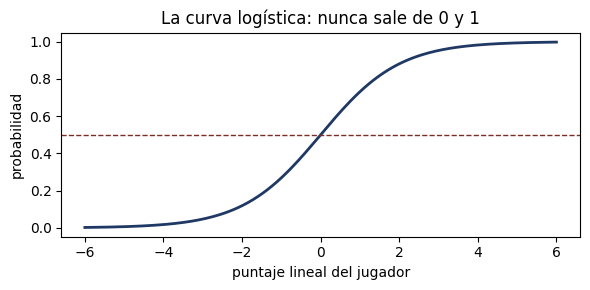

**Qué veo.** La regresión lineal predice «probabilidades» de -0.54 a 1.54; el 25.0 % de los jugadores queda fuera de [0, 1].

**Qué significa.** Una probabilidad negativa o mayor que 1 no existe. La curva logística transforma cualquier puntaje en un número entre 0 y 1.

**Qué decido.** Para un sí o un no, regresión logística.

In [60]:
lineal_bin = Pipeline([("imp", SimpleImputer(strategy="median")), ("esc", StandardScaler()),
                       ("modelo", LinearRegression())]).fit(X_tr, yj_tr)
p_lin = lineal_bin.predict(X_tr)
fuera = 100 * ((p_lin < 0) | (p_lin > 1)).mean()

z = np.linspace(-6, 6, 200)
fig, ax = plt.subplots(figsize=(6, 3))
ax.plot(z, 1 / (1 + np.exp(-z)), color="#1f3864", lw=2); ax.axhline(.5, color="#7b2d26", ls="--", lw=1)
ax.set_xlabel("puntaje lineal del jugador"); ax.set_ylabel("probabilidad"); ax.set_title("La curva logística: nunca sale de 0 y 1")
plt.tight_layout(); plt.show()

md(f"""**Qué veo.** La regresión lineal predice «probabilidades» de {p_lin.min():.2f} a {p_lin.max():.2f}; el {fuera:.1f} % de los jugadores queda fuera de [0, 1].

**Qué significa.** Una probabilidad negativa o mayor que 1 no existe. La curva logística transforma cualquier puntaje en un número entre 0 y 1.

**Qué decido.** Para un sí o un no, regresión logística.""")

## 5. La búsqueda de `C` — solo con el entrenamiento

`C` controla cuánto se castigan los coeficientes grandes: **`C` pequeño = más castigo**, `C` grande = menos (es lo contrario de `alpha` en Ridge y Lasso). Se busca con validación cruzada, midiendo AUC, y solo con el entrenamiento. El modelo del primer intento usaba el `C = 1` por defecto sin comprobar si convenía otro.

In [61]:
CS = [0.001, 0.01, 0.1, 1, 10, 100]
busqueda = GridSearchCV(logistica(), {"modelo__C": CS}, cv=cv_jov, scoring="roc_auc").fit(X_tr, yj_tr)
mejor_C = busqueda.best_params_["modelo__C"]
aucs = busqueda.cv_results_["mean_test_score"]
display(pd.DataFrame({"C": CS, "AUC (validación cruzada)": aucs.round(4)}))

md(f"""**Qué veo.** El mejor valor es `C = {mejor_C}`, con AUC {busqueda.best_score_:.3f}. Los demás valores dan entre {aucs.min():.3f} y {aucs.max():.3f}.

**Qué significa.** {'Las diferencias son de milésimas: el modelo casi no depende de `C`, hay muchas observaciones por variable.' if aucs.max() - aucs.min() < 0.01 else 'El valor de `C` sí cambia el resultado, así que vale la pena haberlo buscado.'}

**Qué decido.** `C = {mejor_C}`. El AUC de validación, {busqueda.best_score_:.3f}, es el número honesto contra el cual se compara la prueba.""")

,C,AUC (validación cruzada)
0,0.001,0.9384
1,0.010,0.9615
2,0.100,0.9656
3,1.000,0.9658
4,10.000,0.9657
5,100.000,0.9657


**Qué veo.** El mejor valor es `C = 1`, con AUC 0.966. Los demás valores dan entre 0.938 y 0.966.

**Qué significa.** El valor de `C` sí cambia el resultado, así que vale la pena haberlo buscado.

**Qué decido.** `C = 1`. El AUC de validación, 0.966, es el número honesto contra el cual se compara la prueba.

## 6. La razón de momios: cuánto multiplica cada habilidad las chances

Una **razón de momios** (odds ratio) de 2 significa que, con todo lo demás igual, las chances de ser de valor alto **se duplican**; una de 0.5, que se reducen a la mitad. Como las variables están estandarizadas, cada razón es por **+1 desviación estándar** de esa habilidad.

In [62]:
modelo = busqueda.best_estimator_
rm = pd.Series(np.exp(modelo.named_steps["modelo"].coef_[0]), index=HAB).sort_values()
display(pd.DataFrame({"reducen las chances": rm.head(6).index, "razón": rm.head(6).round(2).values,
                      "aumentan las chances": rm.tail(6).index[::-1], "razón ": rm.tail(6).round(2).values[::-1]}))

# ¿Algún coeficiente negativo contradice la relación directa con el objetivo?
neg_sospechosos = []
for v in rm.head(6).index:
    r = np.corrcoef(X_tr[v].fillna(X_tr[v].median()), yj_tr)[0, 1]
    if r > 0: neg_sospechosos.append((v, r))
txt_neg = ("; ".join(f"`{v}` (correlación directa con el objetivo: {r:+.2f})" for v, r in neg_sospechosos)
           if neg_sospechosos else "ninguna")

md(f"""**Qué veo.** Con todo lo demás igual, +1 desviación estándar de `{rm.index[-1]}` multiplica las chances por {rm.iloc[-1]:.2f}, y de `{rm.index[-2]}` por {rm.iloc[-2]:.2f}. En el otro extremo, `{rm.index[0]}` las multiplica por {rm.iloc[0]:.2f}. Entre las 6 de razón más baja, las que **aun así** se relacionan positivamente con el valor: {txt_neg}.

**Qué significa.** Una razón menor que 1 no dice «esta habilidad hace daño». Dice que, **una vez conocidas las otras habilidades**, tener más de esta se asocia con menos chances. Aparece cuando varias variables dicen casi lo mismo (`Reactions`, `Composure`, `BallControl`, `ShortPassing`…) y se reparten el efecto, y también porque el modelo mezcla porteros y jugadores de campo en la misma fórmula: las habilidades de portero (`GKDiving`, `GKHandling`…) solo tienen sentido para porteros.

**Qué decido.** Las razones se leen como **ordenamiento de pistas**, no como causas, y no se escribe ninguna conclusión del tipo «mejorar `{rm.index[0]}` baja el valor».""")

,reducen las chances,razón,aumentan las chances,razón
0,Positioning,0.42,Reactions,5.72
1,Vision,0.75,ShortPassing,5.46
2,LongShots,0.79,BallControl,5.29
3,SlidingTackle,0.80,GKDiving,3.13
4,Interceptions,0.83,Composure,2.69
5,Balance,0.84,HeadingAccuracy,2.35


**Qué veo.** Con todo lo demás igual, +1 desviación estándar de `Reactions` multiplica las chances por 5.72, y de `ShortPassing` por 5.46. En el otro extremo, `Positioning` las multiplica por 0.42. Entre las 6 de razón más baja, las que **aun así** se relacionan positivamente con el valor: `Positioning` (correlación directa con el objetivo: +0.36); `Vision` (correlación directa con el objetivo: +0.46); `LongShots` (correlación directa con el objetivo: +0.40); `SlidingTackle` (correlación directa con el objetivo: +0.13); `Interceptions` (correlación directa con el objetivo: +0.19); `Balance` (correlación directa con el objetivo: +0.17).

**Qué significa.** Una razón menor que 1 no dice «esta habilidad hace daño». Dice que, **una vez conocidas las otras habilidades**, tener más de esta se asocia con menos chances. Aparece cuando varias variables dicen casi lo mismo (`Reactions`, `Composure`, `BallControl`, `ShortPassing`…) y se reparten el efecto, y también porque el modelo mezcla porteros y jugadores de campo en la misma fórmula: las habilidades de portero (`GKDiving`, `GKHandling`…) solo tienen sentido para porteros.

**Qué decido.** Las razones se leen como **ordenamiento de pistas**, no como causas, y no se escribe ninguna conclusión del tipo «mejorar `Positioning` baja el valor».

## 7. De la probabilidad a la decisión: ¿a cuántos se revisa?

Se ordena a los jugadores de entrenamiento por probabilidad (calculada con validación cruzada, sin que ningún jugador sea evaluado por un modelo que lo vio) y se mira qué parte de los de valor alto aparece al revisar el X % de la lista. Es la tabla que entiende la dirección deportiva.

In [63]:
prob_cv = cross_val_predict(modelo, X_tr, yj_tr, cv=cv_jov, method="predict_proba")[:, 1]
orden = np.argsort(-prob_cv); elite_ord = yj_tr.values[orden]
base = yj_tr.mean()
filas = []
for fr in [0.05, 0.10, 0.20, 0.30, 0.50]:
    k = int(fr * len(prob_cv))
    filas.append({"se revisa el": f"{int(100 * fr)} %",
                  "% de los de valor alto que se encuentra": round(100 * elite_ord[:k].sum() / yj_tr.sum(), 1),
                  "de cada 100 revisados, son de valor alto": round(100 * elite_ord[:k].mean(), 1),
                  "veces mejor que al azar": round(elite_ord[:k].mean() / base, 1)})
ganancia = pd.DataFrame(filas); display(ganancia)

f20 = ganancia.iloc[2]
md(f"""**Qué veo.** Revisando el 20 % de la lista, se encuentra el {f20.iloc[1]:.1f} % de los jugadores de valor alto, y de cada 100 revisados {f20.iloc[2]:.0f} lo son (al azar serían {100 * base:.0f}): {f20.iloc[3]:.1f} veces mejor que el azar.

**Qué significa.** Con una quinta parte de la revisión se concentra buena parte de los jugadores de valor alto; las siguientes revisiones rinden cada vez menos.

**Qué decido.** A cuántos se revisa depende de cuántas horas de observación hay. La tabla es para la dirección deportiva; el modelo solo ordena.""")

,se revisa el,% de los de valor alto que se encuentra,"de cada 100 revisados, son de valor alto",veces mejor que al azar
0,5 %,21.5,100.0,4.3
1,10 %,42.7,99.0,4.3
2,20 %,75.8,87.9,3.8
3,30 %,91.3,70.5,3.0
4,50 %,98.8,45.8,2.0


**Qué veo.** Revisando el 20 % de la lista, se encuentra el 75.8 % de los jugadores de valor alto, y de cada 100 revisados 88 lo son (al azar serían 23): 3.8 veces mejor que el azar.

**Qué significa.** Con una quinta parte de la revisión se concentra buena parte de los jugadores de valor alto; las siguientes revisiones rinden cada vez menos.

**Qué decido.** A cuántos se revisa depende de cuántas horas de observación hay. La tabla es para la dirección deportiva; el modelo solo ordena.

## 8. La prueba — una sola vez

El modelo (con el `C` ya escogido) se evalúa ahora, por primera y única vez, con los jugadores que no vio.

In [64]:
p_te = modelo.predict_proba(X_te)[:, 1]
auc_te = roc_auc_score(yj_te, p_te)
k = int(0.20 * len(p_te)); top = np.argsort(-p_te)[:k]
captura = yj_te.values[top].sum() / yj_te.sum(); acierto = yj_te.values[top].mean()
cls = (p_te >= 0.5).astype(int)
acc = accuracy_score(yj_te, cls); base_te = max(yj_te.mean(), 1 - yj_te.mean())

print(classification_report(yj_te, cls, target_names=["Valor regular (0)", "Valor alto (1)"]))
display(pd.DataFrame(confusion_matrix(yj_te, cls), index=["real: regular", "real: alto"], columns=["predicho: regular", "predicho: alto"]))

md(f"""**Qué veo.** En la prueba, el AUC es {auc_te:.3f} (validación cruzada: {busqueda.best_score_:.3f}). Revisando el 20 % de la lista se encuentra el {100 * captura:.1f} % de los jugadores de valor alto, y {100 * acierto:.0f} de cada 100 revisados lo son (al azar: {100 * yj_te.mean():.0f}). Con corte en 0.5, la exactitud es {100 * acc:.1f} % contra {100 * base_te:.1f} % de la línea base.

**Qué significa.** {'El modelo se sostuvo con jugadores que no vio: el AUC de la prueba está en línea con el de validación.' if abs(auc_te - busqueda.best_score_) < 0.02 else 'Ojo: el AUC de la prueba se aleja del de validación; conviene revisar la partición.'} La exactitud de {100 * acc:.1f} % solo se entiende frente a la línea base de {100 * base_te:.1f} %: la mejora real es de {100 * (acc - base_te):.1f} puntos. El corte en 0.5 es una convención, no una decisión de negocio: con otro corte cambian precisión y cobertura, pero no el orden de la lista.

**Qué decido — la frase de negocio.** *Con la lista del modelo, de cada 100 jóvenes revisados en el 20 % superior, {100 * acierto:.0f} son de valor alto; revisando al azar serían {100 * yj_te.mean():.0f}. Y con ese 20 % de la revisión se encuentra el {100 * captura:.0f} % de los jóvenes de valor alto, solo con lo que hacen en la cancha.*""")

                   precision    recall  f1-score   support

Valor regular (0)       0.94      0.95      0.94      1128
   Valor alto (1)       0.82      0.79      0.81       341

         accuracy                           0.91      1469
        macro avg       0.88      0.87      0.88      1469
     weighted avg       0.91      0.91      0.91      1469



,predicho: regular,predicho: alto
real: regular,1069,59
real: alto,70,271


**Qué veo.** En la prueba, el AUC es 0.961 (validación cruzada: 0.966). Revisando el 20 % de la lista se encuentra el 75.1 % de los jugadores de valor alto, y 87 de cada 100 revisados lo son (al azar: 23). Con corte en 0.5, la exactitud es 91.2 % contra 76.8 % de la línea base.

**Qué significa.** El modelo se sostuvo con jugadores que no vio: el AUC de la prueba está en línea con el de validación. La exactitud de 91.2 % solo se entiende frente a la línea base de 76.8 %: la mejora real es de 14.4 puntos. El corte en 0.5 es una convención, no una decisión de negocio: con otro corte cambian precisión y cobertura, pero no el orden de la lista.

**Qué decido — la frase de negocio.** *Con la lista del modelo, de cada 100 jóvenes revisados en el 20 % superior, 87 son de valor alto; revisando al azar serían 23. Y con ese 20 % de la revisión se encuentra el 75 % de los jóvenes de valor alto, solo con lo que hacen en la cancha.*

## 9. ¿Bastan pocas variables?

La observación del primer intento («con solo 8 variables se obtiene un rendimiento muy similar») **no tenía código que la respaldara**. Aquí se comprueba: se deja que el propio `Pipeline` escoja las `k` variables de mayor coeficiente **dentro de cada fold** (para que la selección no vea el fold que se evalúa) y se compara el AUC de validación cruzada. La prueba no se vuelve a tocar.

In [67]:
KS = [3, 5, 8, 12, 20]
filas = []
for k_ in KS:
    s = cross_val_score(logistica(C=mejor_C, k=k_), X_tr, yj_tr, cv=cv_jov, scoring="roc_auc")
    filas.append({"variables": k_, "AUC (validación cruzada)": round(s.mean(), 4)})
s_todas = cross_val_score(logistica(C=mejor_C), X_tr, yj_tr, cv=cv_jov, scoring="roc_auc")
filas.append({"variables": f"todas ({len(HAB)})", "AUC (validación cruzada)": round(s_todas.mean(), 4)})
tabla_k = pd.DataFrame(filas); display(tabla_k)

sel8 = logistica(C=mejor_C, k=8).fit(X_tr, yj_tr)
las8 = list(X_tr.columns[sel8.named_steps["sel"].get_support()])
auc8 = tabla_k.loc[tabla_k["variables"] == 8, "AUC (validación cruzada)"].iloc[0]
dif = s_todas.mean() - auc8

md(f"""**Qué veo.** Con 8 variables el AUC de validación es {auc8:.3f}; con las {len(HAB)}, {s_todas.mean():.3f} (diferencia: {dif:.3f}). Las 8 variables escogidas sobre todo el entrenamiento son: {', '.join(f'`{v}`' for v in las8)}.

**Qué significa.** {'La pérdida es muy pequeña: casi todo lo que el modelo sabe está en pocas habilidades, que son además las que más se parecen entre sí.' if dif < 0.01 else 'La pérdida no es despreciable: las demás habilidades sí aportan al orden de la lista.'}

**Qué decido.** {'Para explicarle el modelo a la dirección deportiva se puede usar la versión de 8 variables; para ordenar la lista se mantiene el modelo completo, que no cuesta más de calcular.' if dif < 0.01 else 'Se mantiene el modelo completo; la versión corta queda como apoyo para explicar.'}""")

,variables,AUC (validación cruzada)
0,3,0.9332
1,5,0.9549
2,8,0.9598
3,12,0.9637
4,20,0.9662
5,todas (39),0.9658


**Qué veo.** Con 8 variables el AUC de validación es 0.960; con las 39, 0.966 (diferencia: 0.006). Las 8 variables escogidas sobre todo el entrenamiento son: `HeadingAccuracy`, `ShortPassing`, `BallControl`, `Reactions`, `Positioning`, `Composure`, `GKDiving`, `GKHandling`.

**Qué significa.** La pérdida es muy pequeña: casi todo lo que el modelo sabe está en pocas habilidades, que son además las que más se parecen entre sí.

**Qué decido.** Para explicarle el modelo a la dirección deportiva se puede usar la versión de 8 variables; para ordenar la lista se mantiene el modelo completo, que no cuesta más de calcular.

## 10. Cierre de la regresión logística

1. La regresión logística predice **una probabilidad**, que nunca sale de 0 y 1; la lineal, no.
2. **La exactitud se lee contra la línea base.** Con clases desbalanceadas, acertar mucho no significa saber mucho. Para ordenar una lista, la métrica es el **AUC** y la tabla de captura.
3. La **razón de momios** dice cuánto multiplica cada habilidad las chances **si todo lo demás queda igual**. Un coeficiente negativo en una variable correlacionada con otras no significa que «haga daño».
4. **El objetivo se define antes de modelar y se limita lo que puede decir:** este modelo ordena a los jóvenes que hoy valen mucho; no detecta «promesas», porque `Potential` quedó fuera.
5. **Lo que se afirma se respalda con código:** «con 8 variables rinde igual» ahora tiene una tabla; antes era una frase.
6. **El corte lo pone el negocio:** a cuántos se revisa es una decisión de recursos, no de estadística. La prueba se toca una sola vez.

In [68]:
df = df_todo.copy()

---

# Regularización: Ridge y Lasso para predecir `Value`

Hasta aquí el notebook queda como estaba: perfilado, limpieza, imputación, mapeo de posiciones y listas de variables. Desde aquí empieza la parte nueva: se arman **tres DataFrames** (categórica, categórica + numérica y one-hot) y se aplican **Ridge y Lasso** para predecir el valor de mercado.

La estructura sigue S17 (regresión lineal) y S18 (regresión logística): la métrica se escribe antes, todo va dentro de un `Pipeline`, el hiperparámetro se elige solo con el entrenamiento y la prueba se toca una vez. Cada resultado se lee en tres frases: **qué veo · qué significa · qué decido**.

## 1. El caso y la métrica — escritos antes

Un club quiere una **primera estimación del valor de mercado** de un jugador a partir de sus atributos, antes de que lo revise un analista. El valor real lo fija el mercado; el modelo dice por dónde empezar.

**Métrica que manda: el error absoluto medio (MAE), en euros**, como en S17: «el modelo se equivoca, en promedio, en tantos euros». Al lado se reportan el **RMSE**, que castiga más los errores grandes (equivocarse en 20 M en una estrella pesa), y el **R²**.

**Ridge y Lasso** son una regresión lineal con una penalización que castiga los coeficientes grandes:

* **Ridge (L2)** los encoge a todos hacia cero, pero ninguno llega a cero.
* **Lasso (L1)** los encoge y además **apaga** variables: deja su coeficiente exactamente en 0.

La fuerza del castigo es `alpha`. Ojo con la diferencia con S18: allá era `C` y `C` grande = menos castigo; aquí **`alpha` grande = más castigo**. `alpha` se elige con `GridSearchCV` y MAE, solo con el entrenamiento.

In [69]:
import warnings; warnings.filterwarnings("ignore")
from sklearn.model_selection import KFold, GridSearchCV, cross_validate
from sklearn.compose import TransformedTargetRegressor
from sklearn.linear_model import Ridge, Lasso
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
SEMILLA = 2026
print("Jugadores en df limpio:", len(df))

Jugadores en df limpio: 18147


## 2. Perfilar el objetivo: `Value` y sus ceros

Value = 0: 240 jugadores (1.3 %)
  sin club: 95.4 % | Wage = 0: 95.4 %
  Overall mediano de esos jugadores: 68 (todos: 66)


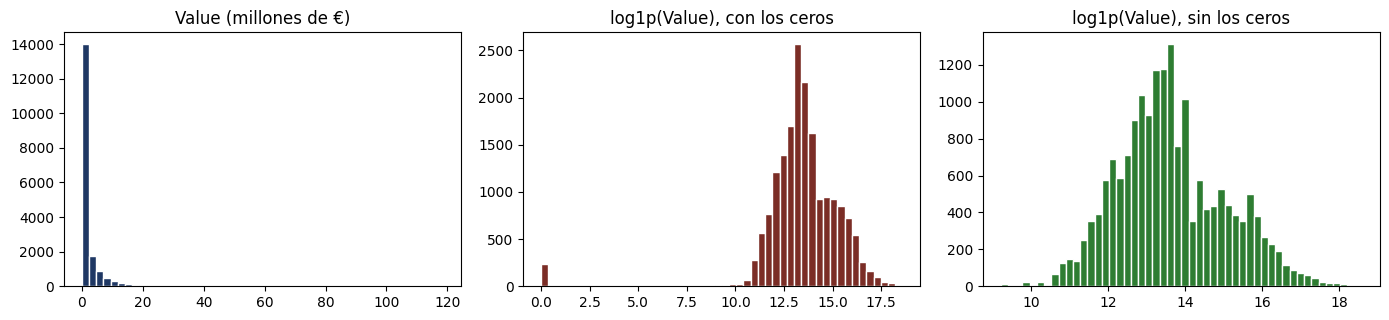

Asimetría — Value: 7.06 | log1p con ceros: -3.28 | log1p sin ceros: 0.38


In [70]:
ceros = df[df["Value"] == 0]
print(f"Value = 0: {len(ceros)} jugadores ({100 * len(ceros) / len(df):.1f} %)")
print(f"  sin club: {100 * (ceros['Club'] == 'Sin club').mean():.1f} % | Wage = 0: {100 * (ceros['Wage'] == 0).mean():.1f} %")
print(f"  Overall mediano de esos jugadores: {ceros['Overall'].median():.0f} (todos: {df['Overall'].median():.0f})")

fig, ax = plt.subplots(1, 3, figsize=(14, 3.3))
ax[0].hist(df["Value"] / 1e6, bins=50, color="#1f3864", edgecolor="white"); ax[0].set_title("Value (millones de €)")
ax[1].hist(np.log1p(df["Value"]), bins=50, color="#7b2d26", edgecolor="white"); ax[1].set_title("log1p(Value), con los ceros")
ax[2].hist(np.log1p(df.loc[df["Value"] > 0, "Value"]), bins=50, color="#2e7d32", edgecolor="white"); ax[2].set_title("log1p(Value), sin los ceros")
plt.tight_layout(); plt.show()
print("Asimetría — Value:", round(df["Value"].skew(), 2),
      "| log1p con ceros:", round(np.log1p(df["Value"]).skew(), 2),
      "| log1p sin ceros:", round(np.log1p(df.loc[df["Value"] > 0, "Value"]).skew(), 2))

**Qué veo.** 240 jugadores (1,3 %) tienen `Value = 0`; el 95,4 % está «Sin club» y con `Wage = 0`. Su `Overall` mediano es 68, más alto que el de todos (66). La asimetría de `Value` es 7,06; con `log1p` y los ceros queda en −3,28; sin los ceros, en 0,38.

**Qué significa.** Un jugador de 68 de media no vale cero euros: son agentes libres sin valoración en el juego. Los ceros no son un precio, son un dato ausente, y en logaritmo se vuelven una cola enorme hacia la izquierda.

**Qué decido.** Esos 240 salen del modelo de `Value` (siguen en `df`). Quedan 17.907 jugadores y un objetivo en logaritmo casi simétrico.

In [71]:
sin_clausula = df["Release Clause"] == 0
print(f"Release Clause = 0: {int(sin_clausula.sum())} jugadores ({100 * sin_clausula.mean():.1f} %)")
vivos = df["Value"] > 0
print(f"Entre los jugadores con Value > 0: Release Clause = 0 en {int((df.loc[vivos, 'Release Clause'] == 0).sum())}, is_loaned = 1 en {int(df.loc[vivos, 'is_loaned'].sum())}, "
      f"coinciden fila a fila en {100 * ((df.loc[vivos, 'Release Clause'] == 0) == (df.loc[vivos, 'is_loaned'] == 1)).mean():.1f} %")
con_clausula = df.loc[df["Release Clause"] > 0, "Release Clause"]
print(f"log1p de la cláusula más baja que existe: {np.log1p(con_clausula.min()):.1f} | log1p(0) = {np.log1p(0):.1f}")

Release Clause = 0: 1504 jugadores (8.3 %)
Entre los jugadores con Value > 0: Release Clause = 0 en 1264, is_loaned = 1 en 1264, coinciden fila a fila en 100.0 %
log1p de la cláusula más baja que existe: 9.5 | log1p(0) = 0.0


**Qué veo.** Entre los jugadores con `Value > 0`, `Release Clause = 0` en 1.264 y `is_loaned = 1` en otros 1.264, y coinciden fila a fila en el 100 %. La cláusula más baja que existe tiene `log1p` de 9,5; `log1p(0)` es 0.

**Qué significa.** Ese 0 no es «cláusula de 1 €»: es «sin cláusula» (los cedidos no la tienen), el mismo caso del −1 de `pdays` en S18. Como número, el logaritmo pondría a esos jugadores muy lejos de todos los demás y obligaría al modelo a corregirlo con coeficientes enormes (en una primera versión `is_loaned` salía con +240 % por desviación estándar, un artefacto).

**Qué decido.** `RC_log` queda vacío donde no hay cláusula y el `Pipeline` lo rellena con la mediana; `is_loaned`, que ya existe, hace de indicador de «sin cláusula». La limpieza de arriba no se toca: `Release Clause` sigue imputada con 0 en `df`.

In [72]:
# Los Value = 0 salen del modelo de Value (siguen en df).
df_modelo = df[df["Value"] > 0].copy()
df_modelo["Wage_log"] = np.log1p(df_modelo["Wage"])
# RC_log: logaritmo de la cláusula solo donde existe; donde no hay cláusula queda vacío (el Pipeline lo rellena con la mediana)
df_modelo["RC_log"] = np.where(df_modelo["Release Clause"] > 0, np.log1p(df_modelo["Release Clause"]), np.nan)
print("Quedan", len(df_modelo), "jugadores de", len(df), "| RC_log vacío en", int(df_modelo["RC_log"].isna().sum()))

Quedan 17907 jugadores de 18147 | RC_log vacío en 1264


## 3. Los tres DataFrames

Se arman a partir de `df_modelo`, usando las listas de variables ya definidas arriba:

* **`df_categorica`**: solo las variables categóricas (más `Value`, el objetivo).
* **`df_cat_num`**: las categóricas y las numéricas juntas.
* **`df_ohe`**: el mismo `df_cat_num`, pero con las categóricas ya convertidas en columnas 0/1 (one-hot, `pd.get_dummies`). Es una matriz 100 % numérica.

**Categóricas:** `columnas_importantes_categoricas` (`Work Rate`, `Preferred Foot`, `Body Type`, `Club`, `Nationality`) más `Position_Group`, la versión ya agrupada de `Position` (8 grupos en vez de 27 posiciones).

**Numéricas:** `variables_numericas` sin `ID` (es un identificador), `Jersey Number` (el dorsal no describe al jugador) ni `Value` (es el objetivo), más `International Reputation`. `Wage` y `Release Clause` entran en logaritmo (`Wage_log`, `RC_log`), como se hizo con `log1p` en el taller de normalización: son variables muy asimétricas. En `RC_log` los jugadores sin cláusula quedan vacíos (ver sección 2).

In [73]:
CATEGORICAS = columnas_importantes_categoricas + ["Position_Group"]
EXCLUIR = ["ID", "Value", "Jersey Number", "Wage", "Release Clause"]
NUMERICAS = [c for c in variables_numericas if c not in EXCLUIR] + ["International Reputation", "Wage_log", "RC_log"]
print(f"{len(CATEGORICAS)} categóricas: {CATEGORICAS}")
print(f"{len(NUMERICAS)} numéricas")

6 categóricas: ['Work Rate', 'Preferred Foot', 'Body Type', 'Club', 'Nationality', 'Position_Group']
45 numéricas


In [74]:
df_categorica = df_modelo[CATEGORICAS + ["Value"]].copy()
df_cat_num = df_modelo[CATEGORICAS + NUMERICAS + ["Value"]].copy()
df_ohe = pd.get_dummies(df_cat_num, columns=CATEGORICAS, dtype=int)
COLS_DUMMIES = [c for c in df_ohe.columns if c not in NUMERICAS + ["Value"]]

resumen_dfs = pd.DataFrame({
    "filas": [d.shape[0] for d in (df_categorica, df_cat_num, df_ohe)],
    "columnas": [d.shape[1] for d in (df_categorica, df_cat_num, df_ohe)],
    "categóricas (texto)": [d.select_dtypes(exclude="number").shape[1] for d in (df_categorica, df_cat_num, df_ohe)],
}, index=["df_categorica", "df_cat_num", "df_ohe"])
display(resumen_dfs)

print("\nColumnas 0/1 que sale de cada categórica en df_ohe:")
display(pd.Series({c: sum(n.startswith(c + "_") for n in COLS_DUMMIES) for c in CATEGORICAS}).to_frame("columnas"))
display(df_ohe[["Overall", "Value"] + COLS_DUMMIES[:4]].head())

,filas,columnas,categóricas (texto)
df_categorica,17907,7,6
df_cat_num,17907,52,6
df_ohe,17907,882,0



Columnas 0/1 que sale de cada categórica en df_ohe:


,columnas
Work Rate,9
Preferred Foot,2
Body Type,3
Club,651
Nationality,163
Position_Group,8


,Overall,Value,Work Rate_High/ High,Work Rate_High/ Low,Work Rate_High/ Medium,Work Rate_Low/ High
0,94,110500000.0,0,0,0,0
1,94,77000000.0,0,1,0,0
2,92,118500000.0,0,0,1,0
3,91,72000000.0,0,0,0,0
4,91,102000000.0,1,0,0,0


**Qué veo.** Los tres DataFrames tienen las mismas 17.907 filas; `df_ohe` pasa de 52 a 882 columnas, casi todas por `Club` (651) y `Nationality` (163).

**Qué significa.** Nótese que `Nationality` tiene 163 columnas en `df_ohe` pero solo 157 aparecen en el entrenamiento: 6 nacionalidades están únicamente en la prueba. En el escenario C esas columnas existen pero valen siempre 0 en entrenamiento; en B el `OneHotEncoder(handle_unknown="ignore")` las ignora al predecir.

**Qué decido.** Se corren A, B y C. B y C tienen la misma información, así que sirven para comprobar que hacer el one-hot antes o dentro del `Pipeline` da lo mismo aquí.

## 4. La partición y el preprocesador

La prueba se aparta **ahora** y no se toca hasta la sección 10. La misma partición (por índice) sirve para los tres DataFrames, así la comparación es justa.

El preprocesador va **dentro del `Pipeline`**: se ajusta solo con el entrenamiento de cada fold. Las numéricas se imputan con la mediana (solo `RC_log` tiene vacíos) y se estandarizan (la penalización de Ridge/Lasso depende de la escala: sin estandarizar, castigaría distinto a una variable en euros que a una en puntos). Las categóricas pasan por `OneHotEncoder`. Como `Value` es muy asimétrico, el objetivo se modela en logaritmo con `TransformedTargetRegressor`, como en S17, y las métricas se calculan en euros.

Tres escenarios, uno por DataFrame:

* **A**: `df_categorica`, solo categóricas.
* **B**: `df_cat_num`, categóricas + numéricas (one-hot dentro del `Pipeline`).
* **C**: `df_ohe`, el one-hot ya hecho (las numéricas se tratan igual; las columnas 0/1 pasan tal cual).

In [75]:
idx_tr, idx_te = train_test_split(df_modelo.index, test_size=0.2, random_state=SEMILLA)
y_tr, y_te = df_modelo.loc[idx_tr, "Value"], df_modelo.loc[idx_te, "Value"]
print("Entrenamiento:", len(idx_tr), "| Prueba:", len(idx_te))

ESCENARIOS = {
    "A. Solo categóricas":        dict(datos=df_categorica, cats=CATEGORICAS, nums=[],         dummies=[]),
    "B. Categóricas + numéricas": dict(datos=df_cat_num,    cats=CATEGORICAS, nums=NUMERICAS,  dummies=[]),
    "C. One-hot (df_ohe)":        dict(datos=df_ohe,        cats=[],          nums=NUMERICAS,  dummies=COLS_DUMMIES),
}

def columnas(cfg):
    return cfg["cats"] + cfg["nums"] + cfg["dummies"]

def construir(modelo, cfg, log=True):
    partes = []
    if cfg["nums"]:    partes.append(("num", Pipeline([("imputador", SimpleImputer(strategy="median")), ("escalador", StandardScaler())]), cfg["nums"]))
    if cfg["cats"]:    partes.append(("cat", OneHotEncoder(handle_unknown="ignore"), cfg["cats"]))
    if cfg["dummies"]: partes.append(("ohe", "passthrough", cfg["dummies"]))
    pipe = Pipeline([("prep", ColumnTransformer(partes)), ("modelo", modelo)])
    if not log:
        return pipe
    return TransformedTargetRegressor(regressor=pipe, func=np.log1p, inverse_func=np.expm1)

kf = KFold(n_splits=5, shuffle=True, random_state=SEMILLA)
METRICAS = {"MAE": "neg_mean_absolute_error", "RMSE": "neg_root_mean_squared_error", "R2": "r2"}

Entrenamiento: 14325 | Prueba: 3582


## 5. ¿Euros o logaritmo? Se decide antes de regularizar

Con una regresión lineal sin penalización (escenario B) se comparan tres formas de plantear el problema, con validación cruzada solo sobre el entrenamiento.

In [76]:
cfg_euros = dict(datos=df_modelo, cats=CATEGORICAS, dummies=[],
                 nums=[c for c in NUMERICAS if c not in ("Wage_log", "RC_log")] + ["Wage", "Release Clause"])
cfg_log = ESCENARIOS["B. Categóricas + numéricas"]

def medir(modelo, cfg, log):
    r = cross_validate(construir(modelo, cfg, log=log), cfg["datos"].loc[idx_tr, columnas(cfg)], y_tr, cv=kf, scoring=METRICAS)
    return {"MAE (€)": round(-r["test_MAE"].mean()), "RMSE (€)": round(-r["test_RMSE"].mean()), "R²": round(r["test_R2"].mean(), 3)}

tabla_log = pd.DataFrame([
    {"planteamiento": "Value en euros, Wage y Release Clause en euros",     **medir(LinearRegression(), cfg_euros, log=False)},
    {"planteamiento": "log(Value), Wage y Release Clause en euros",         **medir(LinearRegression(), cfg_euros, log=True)},
    {"planteamiento": "log(Value), Wage y Release Clause en log (elegido)", **medir(LinearRegression(), cfg_log,   log=True)},
]).set_index("planteamiento")
display(tabla_log)

,MAE (€),RMSE (€),R²
planteamiento,,,
"Value en euros, Wage y Release Clause en euros",475827,1074062,0.964
"log(Value), Wage y Release Clause en euros",500415,3066571,0.673
"log(Value), Wage y Release Clause en log (elegido)",365151,1649082,0.914


**Qué veo.** En euros: MAE 475.825 €, RMSE 1,07 M, R² 0,964. En logaritmo con `Wage` y `Release Clause` en euros: MAE 500.420 €, R² 0,673. En logaritmo con las dos también en log: MAE 365.154 €, RMSE 1,65 M, R² 0,914.

**Qué significa.** El logaritmo solo ayuda si las variables monetarias también van en logaritmo. Y hay un costo: el planteamiento en euros tiene mejor RMSE y R² porque acierta más en las estrellas, que pesan mucho en esas dos métricas.

**Qué decido.** Como la métrica que manda es el MAE (el jugador típico), se queda el logaritmo con `Wage_log` y `RC_log`. Si al club le importaran sobre todo las superestrellas, la decisión sería la contraria.

## 6. Ridge y Lasso: la búsqueda de `alpha` — solo con el entrenamiento

Para cada escenario se compara la regresión **sin regularizar** con Ridge y Lasso. `alpha` se elige con `GridSearchCV` (5 folds, MAE). Lasso usa una rejilla de `alpha` más pequeña que Ridge porque penaliza de forma distinta (L1 apaga variables con valores mucho menores).

In [ ]:
GRILLAS = {
    "Ridge": (Ridge(),               np.logspace(-4, 3, 15)),
    "Lasso": (Lasso(max_iter=20000), np.logspace(-4, -0.5, 8)),
}

def buscar(cfg, nombre):
    modelo, alfas = GRILLAS[nombre]
    return GridSearchCV(construir(modelo, cfg), {"regressor__modelo__alpha": alfas},
                        cv=kf, scoring=METRICAS, refit="MAE", n_jobs=-1
                       ).fit(cfg["datos"].loc[idx_tr, columnas(cfg)], y_tr)

def fila_busqueda(gs, escenario, nombre):
    i = gs.best_index_
    coef = gs.best_estimator_.regressor_.named_steps["modelo"].coef_
    return {"escenario": escenario, "modelo": nombre, "alpha": gs.best_params_["regressor__modelo__alpha"],
            "MAE (€)": round(-gs.cv_results_["mean_test_MAE"][i]), "± MAE (€)": round(gs.cv_results_["std_test_MAE"][i]), "RMSE (€)": round(-gs.cv_results_["mean_test_RMSE"][i]),
            "R²": round(gs.cv_results_["mean_test_R2"][i], 3),
            "coef ≠ 0": f"{int((coef != 0).sum())} de {len(coef)}"}

busquedas, filas = {}, []
for esc, cfg in ESCENARIOS.items():
    r = cross_validate(construir(LinearRegression(), cfg), cfg["datos"].loc[idx_tr, columnas(cfg)], y_tr, cv=kf, scoring=METRICAS)
    filas.append({"escenario": esc, "modelo": "Sin regularizar", "alpha": np.nan,
                  "MAE (€)": round(-r["test_MAE"].mean()), "± MAE (€)": round(r["test_MAE"].std()), "RMSE (€)": round(-r["test_RMSE"].mean()), "R²": round(r["test_R2"].mean(), 3),
                  "coef ≠ 0": "—"})
    for nombre in GRILLAS:
        busquedas[(esc, nombre)] = buscar(cfg, nombre)
        filas.append(fila_busqueda(busquedas[(esc, nombre)], esc, nombre))

tabla_busqueda = pd.DataFrame(filas).set_index(["escenario", "modelo"])
display(tabla_busqueda)

**Qué veo.** Con numéricas (B y C), el MAE de validación es 365.154 € sin regularizar, 365.548 € con Ridge y 355.202 € con Lasso; la desviación entre folds es de unos 30.000 €. Lasso (alpha ≈ 0,03) deja solo 11 de 875 coeficientes. Con solo categóricas (A) el R² es 0,37 y el MAE ≈ 1,61 M. B y C dan lo mismo.

**Qué significa.** Ridge no mejora nada: hay 14.325 jugadores para ~875 columnas y la señal es fuerte, así que casi no hay sobreajuste que frenar. Lasso tampoco empeora: con 11 variables logra el mismo error (la diferencia de ~10.000 € está dentro del ruido entre folds). Las categóricas solas explican poco.

**Qué decido.** Ridge se queda como referencia. Lasso es el candidato porque hace lo mismo con una fracción de las variables.

## 7. Qué hace cada penalización

Izquierda: el MAE de validación según `alpha` para los tres escenarios. Derecha: los **caminos de los coeficientes** de las variables numéricas del escenario B a medida que sube `alpha`: Ridge los encoge todos sin apagar ninguno; Lasso los lleva a cero uno por uno.

In [ ]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4))
for a, nombre in zip(ax, GRILLAS):
    for esc in ESCENARIOS:
        gs = busquedas[(esc, nombre)]
        alfas = gs.cv_results_["param_regressor__modelo__alpha"].data.astype(float)
        mae = -gs.cv_results_["mean_test_MAE"] / 1000
        a.plot(alfas, mae, "o-", label=esc)
        a.plot(gs.best_params_["regressor__modelo__alpha"], -gs.best_score_ / 1000, "k*", markersize=13)
    a.set_xscale("log"); a.set_xlabel("alpha"); a.set_ylabel("MAE de validación (miles de €)"); a.set_title(nombre + " (★ = mejor alpha)")
    a.grid(alpha=.3)
ax[0].legend(fontsize=8)
plt.tight_layout(); plt.show()

In [ ]:
cfgB = ESCENARIOS["B. Categóricas + numéricas"]
XtrB = cfgB["datos"].loc[idx_tr, columnas(cfgB)]
rejillas_camino = {"Ridge": np.logspace(-3, 4, 12), "Lasso": np.logspace(-4, 0, 9)}

fig, ax = plt.subplots(1, 2, figsize=(13, 4.3))
for a, nombre in zip(ax, GRILLAS):
    modelo, _ = GRILLAS[nombre]
    caminos = []
    for alfa in rejillas_camino[nombre]:
        m = construir(clone(modelo).set_params(alpha=alfa), cfgB).fit(XtrB, y_tr)
        caminos.append(m.regressor_.named_steps["modelo"].coef_[:len(NUMERICAS)])   # las numéricas van primero
    caminos = pd.DataFrame(caminos, index=rejillas_camino[nombre], columns=NUMERICAS)
    destacadas = caminos.abs().max().sort_values(ascending=False).head(6).index
    for c in NUMERICAS:
        if c not in destacadas:
            a.plot(caminos.index, caminos[c], color="#bbbbbb", lw=.8)
    for c in destacadas:
        a.plot(caminos.index, caminos[c], lw=2, label=c)
    a.axvline(busquedas[("B. Categóricas + numéricas", nombre)].best_params_["regressor__modelo__alpha"], color="k", ls="--", lw=1)
    a.set_xscale("log"); a.set_xlabel("alpha"); a.set_ylabel("coeficiente (escala log de Value)"); a.set_title(f"Camino de los coeficientes — {nombre}")
    a.legend(fontsize=7, ncol=2); a.grid(alpha=.3)
plt.tight_layout(); plt.show()

## 8. Leer los coeficientes

Como el objetivo está en logaritmo y las numéricas están estandarizadas, cada coeficiente se lee como en S17: `(exp(coef) − 1) × 100` es el **cambio porcentual del valor por +1 desviación estándar** de esa variable, con todo lo demás igual. Primero, cuántas columnas dejó vivas Lasso en cada categórica; después, las numéricas de Lasso y Ridge lado a lado.

In [ ]:
def coeficientes(gs):
    pipe = gs.best_estimator_.regressor_
    return pd.Series(pipe.named_steps["modelo"].coef_, index=pipe.named_steps["prep"].get_feature_names_out())

B = "B. Categóricas + numéricas"
coef_lasso, coef_ridge = coeficientes(busquedas[(B, "Lasso")]), coeficientes(busquedas[(B, "Ridge")])

# ¿Cuántas columnas de cada categórica sobreviven en Lasso?
sobrevive = pd.DataFrame({
    "columnas 0/1": {c: sum(n.startswith(f"cat__{c}_") for n in coef_lasso.index) for c in CATEGORICAS},
    "vivas en Lasso": {c: int(sum((coef_lasso[n] != 0) for n in coef_lasso.index if n.startswith(f"cat__{c}_")) ) for c in CATEGORICAS},
})
sobrevive.loc["(numéricas)"] = [len(NUMERICAS), int((coef_lasso[[f"num__{c}" for c in NUMERICAS]] != 0).sum())]
print(f"Lasso (alpha = {busquedas[(B, 'Lasso')].best_params_['regressor__modelo__alpha']:.4g}) dejó {int((coef_lasso != 0).sum())} de {len(coef_lasso)} coeficientes distintos de cero")
display(sobrevive)

num = pd.DataFrame({
    "Lasso (% por +1 DE)": ((np.exp(coef_lasso[[f"num__{c}" for c in NUMERICAS]].values) - 1) * 100).round(2),
    "Ridge (% por +1 DE)": ((np.exp(coef_ridge[[f"num__{c}" for c in NUMERICAS]].values) - 1) * 100).round(2),
}, index=NUMERICAS)
print("\nNuméricas, ordenadas por |efecto| en Ridge (las 15 primeras):")
display(num.reindex(num["Ridge (% por +1 DE)"].abs().sort_values(ascending=False).index).head(15))
print("Numéricas que Lasso dejó vivas:", ", ".join(num.index[num["Lasso (% por +1 DE)"] != 0]))

**Qué veo.** Lasso apaga todas las columnas de `Club`, `Nationality`, `Work Rate`, `Preferred Foot`, `Body Type` y `Position_Group`, y deja 11 numéricas: `Overall`, `RC_log`, `Age`, `Wage_log`, `Potential`, `Skill Moves`, `Finishing`, `Volleys`, `SprintSpeed`, `Positioning` e `is_loaned`. Por +1 desviación estándar, `Overall` sube el valor ≈ 119 % en Lasso y 169 % en Ridge; `Age` lo baja 15 % y 28 %.

**Qué significa.** Una vez conocidos el `Overall`, la cláusula, el salario y la edad, saber el club o la nacionalidad no aporta. Ridge reparte el efecto entre variables parecidas (`Overall`, `Potential`, `Reactions`…) y Lasso se queda con una: por eso sus coeficientes difieren (igual que `GarageCars` y `GarageArea` en S17). Ninguno se lee sin mirar a los demás, y un coeficiente no es causa.

**Qué decido.** Para explicar el valor, las palancas son la calidad (`Overall`), la edad y lo que el mercado ya fijó en el contrato.

## 9. Dos variables que casi son el objetivo: `Wage` y `Release Clause`

`Release Clause` y `Wage` son números que el propio juego calcula a partir del valor del jugador. Aquí se mira cuánto se parece `Release Clause` a `Value` y, siguiendo la lógica de S18 con `duration` (una variable que se conoce *después* del hecho no sirve para decidir), cuánto cambia el resultado **sin** ellas.

In [ ]:
con_clausula = df_modelo[df_modelo["Release Clause"] > 0]
razon = con_clausula["Release Clause"] / con_clausula["Value"]
print(f"Release Clause / Value — mediana: {razon.median():.2f} | 5 %–95 %: {razon.quantile(.05):.2f}–{razon.quantile(.95):.2f}")
print("Correlación con Value —",
      "Release Clause:", round(df_modelo["Value"].corr(df_modelo["Release Clause"]), 3),
      "| Wage:", round(df_modelo["Value"].corr(df_modelo["Wage"]), 3),
      "| Overall:", round(df_modelo["Value"].corr(df_modelo["Overall"]), 3))

cfg_sin = dict(ESCENARIOS[B], nums=[c for c in NUMERICAS if c not in ("Wage_log", "RC_log")])
busquedas_sin = {nombre: buscar(cfg_sin, nombre) for nombre in GRILLAS}
filas_sin = [fila_busqueda(busquedas[(B, n)], "B con Wage y Release Clause", n) for n in GRILLAS] + \
            [fila_busqueda(busquedas_sin[n], "B sin Wage ni Release Clause", n) for n in GRILLAS]
display(pd.DataFrame(filas_sin).set_index(["escenario", "modelo"]))

**Qué veo.** `Release Clause` vale en mediana 1,76 veces `Value` y su correlación con `Value` es 0,967 (`Wage` 0,858, `Overall` 0,632). Sin `Wage` ni `Release Clause`, el MAE de validación sube de 355.202 € a 452.122 € (Ridge) y el R² baja de 0,919 a 0,853. Lasso sin ellas necesita 337 columnas y empeora (R² 0,804).

**Qué significa.** Buena parte del acierto sale de leer números que el juego ya calculó a partir del valor. Sirven para tasar a un jugador que ya tiene contrato; no sirven para valorar a uno que todavía no lo tiene.

**Qué decido.** Se reportan los dos modelos: con contrato (Lasso) y sin contrato (Ridge). El segundo es el número honesto para un jugador sin contrato.

## 10. La prueba — una sola vez

Antes de mirar la prueba ya están decididos los dos modelos finales: el mejor de Ridge o Lasso por MAE de validación, en el escenario B, **con** y **sin** `Wage` y `Release Clause`. Cada uno se evalúa una vez sobre los jugadores que no vio.

In [ ]:
def evaluar_prueba(gs, cfg):
    pred = gs.predict(cfg["datos"].loc[idx_te, columnas(cfg)])
    error = (y_te - pred).abs()
    return {"MAE (€)": round(mean_absolute_error(y_te, pred)),
            "RMSE (€)": round(mean_squared_error(y_te, pred) ** .5),
            "R²": round(r2_score(y_te, pred), 3),
            "error relativo mediano (%)": round(100 * (error / y_te).median(), 1),
            "jugadores con error > 20 % (%)": round(100 * (error / y_te > .2).mean(), 1)}

mejor_con = min(GRILLAS, key=lambda n: -busquedas[(B, n)].best_score_)
mejor_sin = min(GRILLAS, key=lambda n: -busquedas_sin[n].best_score_)
print(f"Con Wage y Release Clause: {mejor_con} | Sin ellas: {mejor_sin}")
prueba = pd.DataFrame([
    {"modelo": f"{mejor_con}, con Wage y Release Clause", **evaluar_prueba(busquedas[(B, mejor_con)], ESCENARIOS[B])},
    {"modelo": f"{mejor_sin}, sin Wage ni Release Clause", **evaluar_prueba(busquedas_sin[mejor_sin], cfg_sin)},
]).set_index("modelo")
display(prueba)

**Qué veo.** En la prueba, Lasso con `Wage` y `Release Clause` tiene MAE 347.287 €, R² 0,947, error relativo mediano 9,0 % y 16,9 % de jugadores con error mayor al 20 %. Ridge sin ellas: MAE 421.514 €, R² 0,936, error mediano 13,6 % y 33,0 % con error mayor al 20 %.

**Qué significa.** Los dos se sostuvieron con jugadores que no vieron. El R² de prueba sale más alto que el de validación porque lo dominan unas pocas estrellas que el modelo acierta bien; el MAE y el error relativo cuentan mejor la historia del jugador típico.

**Qué decido — la frase de negocio.** *Con contrato, la estimación queda a menos de 9 euros de cada 100 en la mitad de los jugadores y se equivoca por más del 20 % en 17 de cada 100. Sin contrato, el error mediano sube a casi 14 de cada 100 y 33 de cada 100 pasan del 20 %: esos los revisa el analista primero.*

## 11. Cierre

1. **Un cero que no es un número se lee antes de modelar**: `Release Clause = 0` era «sin cláusula», y tratarlo como número distorsionaba coeficientes y penalización.
2. **Los `Value = 0` eran datos ausentes**, no precios; salieron del modelo.
3. **Ridge no mejoró** a la regresión sin penalizar: con muchos datos y señal fuerte no había sobreajuste que corregir.
4. **Lasso igualó el error con 11 de 875 variables**: el club y la nacionalidad no aportan una vez conocidas la calidad, la edad y el contrato.
5. **Hacer el one-hot antes (C) o dentro del `Pipeline` (B) dio lo mismo**; dentro es más seguro porque no depende de las categorías de la prueba.
6. **`Wage` y `Release Clause` casi son el objetivo**: sin ellas el error crece mucho. Cuál modelo usar depende de si el jugador ya tiene contrato.
7. **La métrica se escogió antes (MAE) y la prueba se tocó una vez**; con RMSE o R² como métrica, el planteamiento en euros habría ganado.

*Siguiente paso posible:* lo mismo con `LogisticRegression` (`penalty="l1"` y `"l2"`) para `Position_Group`, como en S18.